# Which demographic groups are most affected by TBe, PBu, and both together?
This notebook answers the question with data-mining techniques and **15 figures (W1–W15)**. Every figure has a short block saying *what we get* and *why we did it*.

**Four mutually exclusive outcomes per post:** *Neither*, *TBe only*, *PBu only*, *Both* (TBe = thwarted belongingness, PBu = perceived burdensomeness).
**Demographic groups:** age group, gender (manual annotation), plus groups extracted from the post text: student, employed, unemployed / job loss, partner or spouse mentioned, parent, mental-health condition (depression, anxiety). Only groups with ≥20 posts are analysed.

| Technique | Figures |
|---|---|
| Descriptive profiling, overlap (UpSet) | W1, W2 |
| Lift / relative risk, Fisher tests with FDR | W3, W5 |
| Empirical-Bayes shrinkage ranking, Wilson CIs | W4, W15 |
| Multinomial logistic regression (adjusted) | W6 |
| Decision trees, random forest, gradient boosting, permutation importance | W7, W8 |
| Subgroup discovery (Apriori) and intersections | W9, W10, W11 |
| Hierarchical clustering, correspondence analysis | W12, W13 |
| Rate vs reach (bubble) | W14 |

**Inputs:** the ground-truth label CSV and the manual gender/age CSV (same two files as before). **Runtime:** about 5-10 minutes.
**Caveats:** groups are regex-extracted and not manually verified; groups overlap; age is known for 344 posts and gender for 88, so those results have wide uncertainty; people who disclose are not representative of all posters. Associations only, not causes.

## 0. Setup

In [ ]:
import importlib
import subprocess
import sys
import re
import os
import itertools
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, StratifiedKFold
from sklearn.inspection import permutation_importance
from mlxtend.frequent_patterns import apriori

# Suppress warning outputs for cleaner presentation
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
for pkg in ["mlxtend", "statsmodels", "scikit-learn"]:
    try: importlib.import_module("sklearn" if pkg == "scikit-learn" else pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

OUT = "outputs/who/figures/"; os.makedirs(OUT, exist_ok=True)

GT_CSV = "/content/drive/MyDrive/Research/Dataminds/Easy version - ground_truth.csv"
ANNOT_CSV = "/content/drive/MyDrive/Research/Dataminds/gender_annotations - Annotated-gender-age.csv"

assert GT_CSV and ANNOT_CSV, "Set GT_CSV and ANNOT_CSV (see comments above)."

## 1. Data preparation
### 1a. Rule-based demographic extractor

In [ ]:
def _norm(text):
    """Normalize curly quotes to standard straight quotes."""
    return (text.replace("’", "'")
                .replace("‘", "'")
                .replace("“", '"')
                .replace("”", '"'))

# Compilation flags for standard regex matching
FLAGS = re.IGNORECASE
HEDGE_BEFORE = re.compile(
    r"\b(?:when|if|until|once|before|after|wish|turn|turning|by the time|will be|gonna be|going to be)\s*(?:i\s*(?:am|'m|will be)?)?\s*$",
    FLAGS
)

def _hedged(text, pos):
    """Detect if statements are conditional, hypothetical, or future-oriented."""
    return bool(HEDGE_BEFORE.search(text[max(0, pos - 25):pos]))

def _snip(match, limit=60):
    """Extract text snippet around a match to use as validation evidence."""
    s = match.group(0).strip()
    return s if len(s) <= limit else s[:limit] + "..."

# ==================================================================
# 1. AGE EXTRACTION PATTERNS
# ==================================================================
AGE_UNIT = r"(?:\s*-?\s*(?:years?|yrs?)(?:[- ]old)?|\s*yo\b|\s*y/o\b)"

AGE_A = re.compile(
    r"\b(?:i\s?am|i'm|im)\s+(?:currently\s+|only\s+|just\s+|now\s+|a\s+|an\s+)*(\d{1,2})"
    r"(?:(" + AGE_UNIT + r")|(?=\s*(?:[.,;:!?)\]\n]|$|and\b|but\b|so\b|who\b|still\b|never\b|going\b|living\b|struggling\b|"
    r"feeling\b|trying\b|currently\b|male\b|female\b|m\b|f\b|guy\b|girl\b|man\b|woman\b|boy\b)))",
    FLAGS
)

AGE_TURNED = re.compile(r"\bi\s+(?:just\s+)?turned
\s+(\d{2})\b", FLAGS)
AGE_START = re.compile(r"(?:^|[.!?\n]\s*)(\d{1,2})\s?(?:yo|y/o|year[- ]old|yr[- ]old)\s*(?:male|female|man|woman|guy|girl|boy|here)", FLAGS)
AGE_BRACKET = re.compile(r"[\(\[]\s*(?:(\d{1,2})\s?[mf]|[mf]\s?(\d{1,2}))\s*[\)\]]", FLAGS)
AGE_DECADE = re.compile(r"\bi(?:'m| am)\s+in\s+my\s+((?:early|mid|late)[- ])?(teens|20s|30s|40s|50s|60s|twenties|thirties|forties|fifties)\b", FLAGS)
AGE_TEEN = re.compile(r"\bi(?:'m| am)\s+(?:just\s+)?a\s+teen(?:ager)?\b", FLAGS)

def age_group(age):
    """Map numeric age into categorical bins."""
    if age < 18:
        return "under 18"
    elif age <= 24:
        return "18-24"
    elif age <= 34:
        return "25-34"
    elif age <= 44:
        return "35-44"
    else:
        return "45+"

def extract_age(text):
    """Extract numeric age and age groups with supporting match evidence."""
    ages, evidence = [], None

    for rx in (AGE_A, AGE_TURNED, AGE_START, AGE_BRACKET):
        for m in rx.finditer(text):
            val_str = next((g for g in m.groups() if g and g.isdigit()), None)
            if val_str:
                age_val = int(val_str)
                if 12 <= age_val <= 80 and not _hedged(text, m.start()):
                    ages.append(age_val)
                    evidence = evidence or _snip(m)

    if ages:
        if len(set(ages)) > 1:
            return None, "conflicting ages", "conflicting ages: " + ", ".join(map(str, sorted(set(ages))))
        return ages[0], age_group(ages[0]), evidence

    m = AGE_DECADE.search(text)
    if m:
        decade = m.group(2).lower()
        decade = {"twenties": "20s", "thirties": "30s", "forties": "40s", "fifties": "50s"}.get(decade, decade)
        label = ((m.group(1) or "").strip(" -") + " " + decade).strip()
        return None, label, _snip(m)

    m = AGE_TEEN.search(text)
    if m:
        return None, "teen", _snip(m)

    return None, None, None

# ==================================================================
# 2. STUDENT STATUS PATTERNS
# ==================================================================
STU_EXPL = re.compile(r"\bi(?:'m| am)\s+(?:currently\s+|still\s+|a\s+|an\s+)*(?:(high\s?school|college|university|grad(?:uate)?|masters?|phd|med|law|nursing|undergrad(?:uate)?|first[- ]year|freshman|sophomore|junior|senior)\s+)?student\b", FLAGS)
STU_IN = re.compile(r"\bi(?:'m| am)\s+(?:currently\s+|still\s+)?in
\s+(?:my\s+\w+\s+(?:year\s+)?of\s+)?(high\s?school|middle\s+school|college|uni|university|(?:grade|year)\s+\d+|\d+(?:st|nd|rd|th)\s+grade)\b|\bi\s+(?:go|went)\s+to
\s+(?:high\s+)?(school|college|university|uni)\b", FLAGS)
STU_LIKELY = re.compile(r"\bmy\s+(?:school|college|university|uni|classes|exams?|grades|homework|professors?|teachers?|finals|semester|gpa|assignments?|thesis|dissertation|lectures?)\b", FLAGS)

def _level(s):
    """Helper to normalize student academic level."""
    s = (s or "").lower()
    if re.search(r"high|middle|grade|year\s+\d", s):
        return "high school"
    if re.search(r"college|uni|grad|master|phd|med|law|nursing|freshman|sophomore|junior|senior|first", s):
        return "college/university"
    return ""

def extract_student(text):
    """Extract student status and academic levels."""
    for rx in (STU_EXPL, STU_IN):
        m = rx.search(text)
        if m:
            lvl = _level(" ".join(g for g in m.groups() if g))
            return (f"student ({lvl})" if lvl else "student"), _snip(m)
    m = STU_LIKELY.search(text)
    if m:
        return "likely student", _snip(m)
    return None, None

# ==================================================================
# 3. EMPLOYMENT PATTERNS
# ==================================================================
EMP_UN = re.compile(r"\bi(?:'m| am)\s+(?:currently\s+)?(?:unemployed|jobless|out\s+of\s+work)\b|\bi\s+(?:just\s+)?(?:lost\s+my\s+job|got\s+fired|was\s+fired|got\s+laid\s+off|was\s+laid\s+off)\b|\bi\s+(?:don'?t\s+have\s+a\s+job|have\s+no\s+job|can'?t\s+find\s+(?:a\s+)?(?:job|work))\b", FLAGS)
EMP_RET = re.compile(r"\bi(?:'m| am)\s+(?:now\s+)?retired\b", FLAGS)
EMP_EXPL = re.compile(r"\bi\s+work\s+(?:as|at|in|for|full[- ]time|part[- ]time|nights)\b|\bi\s+have\s+a\s+(?:full[- ]time\s+|part[- ]time\s+)?job\b|\bi\s+(?:got|started)\s+a\s+(?:new\s+)?job\b", FLAGS)
EMP_LIKELY = re.compile(r"\bmy\s+(?:job|boss|co-?workers?|manager|workplace|employer|shift|colleagues?)\b", FLAGS)

def extract_employment(text):
    """Identify current self-reported employment status."""
    for rx, val in ((EMP_UN, "unemployed / job loss"), (EMP_RET, "retired"), (EMP_EXPL, "employed"), (EMP_LIKELY, "likely employed")):
        m = rx.search(text)
        if m:
            return val, _snip(m)
    return None, None

# ==================================================================
# 4. PARENTHOOD PATTERNS
# ==================================================================
PAR_A = re.compile(r"\bmy\s+(?:\d+\s+|two\s+|three\s+|four\s+|little\s+|young\s+|newborn\s+|infant\s+)?(?:kids?|children|child|toddler|newborn|infant|sons?|daughters?|twins?)\b", FLAGS)
PAR_B = re.compile(r"\bi(?:'m| am)\s+(?:a\s+|an\s+)?(?:(?:single|stay[- ]at[- ]home|young|new|first[- ]time|proud|teen)\s+)?(?:mom|mother|dad|father|parent|mum)\b", FLAGS)
PAR_C = re.compile(r"\bi\s+have\s+(?:a\s+|\d+\s+|two\s+|three\s+|four\s+)(?:kids?|children|child|son|daughter)\b", FLAGS)

def extract_parent(text):
    """Extract parenthood disclosures."""
    for rx in (PAR_B, PAR_C, PAR_A):
        m = rx.search(text)
        if m:
            return "parent", _snip(m)
    return None, None

# ==================================================================
# 5. MENTAL HEALTH DISCLOSURE PATTERNS
# ==================================================================
COND = {
    "depression": r"(?:major\s+|clinical\s+|severe\s+|chronic\s+)?depression|\bmdd\b",
    "anxiety": r"(?:social\s+|generali[sz]ed\s+|severe\s+)?anxiety(?:\s+disorder)?",
    "bipolar": r"bipolar",
    "ADHD": r"adhd",
    "PTSD": r"c?ptsd",
    "OCD": r"\bocd\b",
    "BPD": r"\bbpd\b|borderline(?:\s+personality\s+disorder)?",
    "autism": r"autis(?:m|tic)|asperger'?s?",
    "schizophrenia": r"schizo\w*",
    "eating disorder": r"anorexia|bulimia|binge[- ]eating(?:\s+disorder)?|eating\s+disorder",
    "panic disorder": r"panic\s+(?:disorder|attacks?)",
    "insomnia": r"insomnia",
}
COND_ALT = "|".join(f"(?P<c{i}>{p})" for i, p in enumerate(COND.values()))
COND_NAMES = list(COND.keys())
DX_RE = re.compile(r"\b(?:i(?:'ve| have)?\s+been|i\s+was|i\s+got|i\s+am|i'm)\s+(?:officially\s+|recently\s+|also\s+|finally\s+)?diagnosed\s+(?:with|as\s+having)\s+([^.!?\n]{0,70})", FLAGS)
SELF_RES = [
    re.compile(r"\bi\s+(?:have|suffer\s+from|struggle\s+with|deal\s+with|live\s+with)\s+(?:\w+\s+){0,2}?(" + COND_ALT + r")", FLAGS),
    re.compile(r"\bmy\s+(?:\w+\s+)?(" + COND_ALT + r")", FLAGS),
    re.compile(r"\bi(?:'m| am)\s+(?:an?\s+)?(autistic|bipolar)\b", FLAGS),
]

def _conds_in(s):
    """Helper to identify which mental health conditions map to regex groups."""
    out = []
    for m in re.finditer(COND_ALT, s, FLAGS):
        name = COND_NAMES[int(m.lastgroup[1:])]
        if name not in out:
            out.append(name)
    return out

def extract_mh(text):
    """Extract diagnosed or self-reported mental health conditions."""
    found, evidence = {}, None
    for m in DX_RE.finditer(text):
        for c in _conds_in(m.group(1)):
            found[c] = "diagnosed"
            evidence = evidence or _snip(m, 80)

    for rx in SELF_RES:
        for m in rx.finditer(text):
            matched_conditions = (_conds_in(m.group(0)) if rx is not SELF_RES[2]
                                  else ["autism" if "autis" in m.group(1).lower() else "bipolar"])
            for c in matched_conditions:
                found.setdefault(c, "self-reported")
                evidence = evidence or _snip(m)

    if not found:
        return None, None
    return "; ".join(f"{c} ({k})" for c, k in found.items()), evidence

# ==================================================================
# 6. REGION / GEOGRAPHY PATTERNS
# ==================================================================
COUNTRIES = {
    "united states": "United States", "usa": "United States", "america": "United States", "the states": "United States",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "england": "United Kingdom", "scotland": "United Kingdom",
    "wales": "United Kingdom", "britain": "United Kingdom", "northern ireland": "United Kingdom",
    "canada": "Canada", "australia": "Australia", "new zealand": "New Zealand", "ireland": "Ireland", "india": "India",
    "germany": "Germany", "france": "France", "italy": "Italy", "spain": "Spain", "portugal": "Portugal", "netherlands": "Netherlands",
    "belgium": "Belgium", "sweden": "Sweden", "norway": "Norway", "denmark": "Denmark", "finland": "Finland", "poland": "Poland",
    "russia": "Russia", "ukraine": "Ukraine", "turkey": "Turkey", "greece": "Greece", "romania": "Romania", "switzerland": "Switzerland",
    "austria": "Austria", "mexico": "Mexico", "brazil": "Brazil", "argentina": "Argentina", "chile": "Chile", "colombia": "Colombia",
    "china": "China", "japan": "Japan", "korea": "South Korea", "south korea": "South Korea", "singapore": "Singapore",
    "malaysia": "Malaysia", "indonesia": "Indonesia", "philippines": "Philippines", "pakistan": "Pakistan", "bangladesh": "Bangladesh",
    "sri lanka": "Sri Lanka", "nepal": "Nepal", "israel": "Israel", "egypt": "Egypt", "saudi arabia": "Saudi Arabia", "uae": "UAE",
    "iran": "Iran", "nigeria": "Nigeria", "south africa": "South Africa", "kenya": "Kenya", "ghana": "Ghana",
}

STATE_LIST = [
    "alabama","alaska","arizona","arkansas","california","colorado","connecticut","delaware","florida","hawaii",
    "idaho","illinois","indiana","iowa","kansas","kentucky","louisiana","maine","maryland","massachusetts",
    "michigan","minnesota","mississippi","missouri","montana","nebraska","nevada","new hampshire","new jersey",
    "new mexico","new york","north carolina","north dakota","ohio","oklahoma","oregon","pennsylvania",
    "rhode island","south carolina","south dakota","tennessee","texas","utah","vermont","virginia",
    "west virginia","wisconsin","wyoming"
]

DEMONYMS = {
    "american": "United States", "british": "United Kingdom", "canadian": "Canada", "australian": "Australia", "indian": "India",
    "german": "Germany", "french": "France", "italian": "Italy", "spanish": "Spain", "mexican": "Mexico", "brazilian": "Brazil",
    "chinese": "China", "japanese": "Japan", "korean": "South Korea", "russian": "Russia", "polish": "Poland", "dutch": "Netherlands",
    "swedish": "Sweden", "norwegian": "Norway", "irish": "Ireland", "scottish": "United Kingdom", "welsh": "United Kingdom",
    "filipino": "Philippines", "pakistani": "Pakistan", "nigerian": "Nigeria", "egyptian": "Egypt", "turkish": "Turkey",
    "iranian": "Iran", "israeli": "Israel", "south african": "South Africa", "new zealander": "New Zealand", "kiwi": "New Zealand",
}

PLACE_ALT = "|".join(sorted(map(re.escape, list(COUNTRIES) + STATE_LIST), key=len, reverse=True))
PLACE_INTRO = re.compile(
    r"\b(?:i(?:'m| am)\s+from|i\s+(?:live|living|grew\s+up|was\s+born|reside|moved)\s+(?:in|to)|i(?:'m| am)\s+(?:currently\s+)?(?:living\s+)?(?:here\s+)?in|here
\s+in)\s+(?:the\s+)?(" + PLACE_ALT + r")\b",
    FLAGS
)
DEMO_RE = re.compile(r"\bi(?:'m| am)\s+(?:an?\s+)?(" + "|".join(sorted(map(re.escape, DEMONYMS), key=len, reverse=True)) + r")\b(?!\s+(?:shepherd|dressing|toast))", FLAGS)

def extract_country(text):
    """Detect country/region disclosures."""
    for m in PLACE_INTRO.finditer(text):
        key = m.group(1).lower()
        if key == "uk" and m.group(1) != "UK":
            continue
        if key == "uae" and m.group(1) != "UAE":
            continue
        if key in COUNTRIES:
            return COUNTRIES[key], _snip(m)
        return "United States", _snip(m) # Maps matched states to US
    m = DEMO_RE.search(text)
    if m:
        return DEMONYMS[m.group(1).lower()], _snip(m)
    return None, None

# ==================================================================
# 7. RELATIONSHIP STATUS PATTERNS
# ==================================================================
REL_EXPL = re.compile(r"\bi(?:'m| am)\s+(?:currently\s+|now\s+|still\s+|recently\s+)?(single|married|divorced|separated|widowed|engaged)\b", FLAGS)
REL_SPOUSE = re.compile(r"\bmy\s+(?:wife|husband|fianc[e  e  ]e?)\b", FLAGS)
REL_PARTNER = re.compile(r"\bmy\s+(?:girlfriend|boyfriend|partner)\b", FLAGS)

def extract_relationship(text):
    """Extract current relationship labels and partner mentions."""
    m = REL_EXPL.search(text)
    if m and not _hedged(text, m.start()):
        return m.group(1).lower(), _snip(m)
    m = REL_SPOUSE.search(text)
    if m:
        return "married/engaged (mentioned spouse)", _snip(m)
    m = REL_PARTNER.search(text)
    if m:
        return "in a relationship (mentioned partner)", _snip(m)
    return None, None

# ==================================================================
# 8. SEXUAL ORIENTATION PATTERNS
# ==================================================================
ORI_WORDS = {
    "gay": "gay", "lesbian": "lesbian", "bi": "bisexual", "bisexual": "bisexual", "pansexual": "pansexual",
    "asexual": "asexual", "straight": "straight", "queer": "queer", "homosexual": "gay", "heterosexual": "straight",
    "demisexual": "demisexual"
}

ORI_RE = re.compile(r"\bi(?:'m| am|\s+identify\s+as|\s+consider\s+myself)\s+(?:a\s+|an\s+)?(?:(?:also|really|openly|totally|kinda|mostly|completely|actually)\s+)?(" +
                    "|".join(ORI_WORDS) + r")(?!\s+(?:up|forward|edge|away|out|as\s+an\s+arrow))", FLAGS)
ORI_CAME = re.compile(r"\bcame\s+out\s+(?:to\s+\w+(?:\s+\w+)?\s+)?as\s+(gay|lesbian|bi|bisexual|pansexual|asexual|queer)(?![\w-])", FLAGS)
UNSURE = re.compile(r"\b(?:think|thinks|maybe|might|wonder|wondering|questioning|not\s+sure|unsure|afraid)\b[^.!?\n]{0,20}$", FLAGS)

def extract_orientation(text):
    """Extract self-disclosed sexual orientation."""
    for rx in (ORI_RE, ORI_CAME):
        for m in rx.finditer(text):
            if _hedged(text, m.start()):
                continue
            val = ORI_WORDS[m.group(1).lower()]
            if UNSURE.search(text[max(0, m.start() - 40):m.start()]):
                val += " (uncertain)"
            return val, _snip(m)
    return None, None

# ==================================================================
# 9. RELIGION PATTERNS
# ==================================================================
REL_WORDS = r"christian|muslim|atheist|agnostic|catholic|jewish|hindu|buddhist|mormon|sikh|orthodox|protestant|religious"
RELIG_RE = re.compile(r"\bi(?:'m| am| was\s+raised| grew\s+up)\s+(?:a\s+|an\s+)?(?:very\s+|devout\s+|strict\s+|practicing\s+|non-practicing\s+)?(" + REL_WORDS + r")\b", FLAGS)

def extract_religion(text):
    """Extract religious affiliations."""
    m = RELIG_RE.search(text)
    if m and not _hedged(text, m.start()):
        return m.group(1).lower(), _snip(m)
    return None, None

# ==================================================================
# 10. RACE / ETHNICITY PATTERNS
# ==================================================================
RACE_RE = re.compile(r"\bi(?:'m| am)\s+(?:a\s+|an\s+)?(?:half[- ]|part[- ]|mixed[- ])?(black|white|asian|hispanic|latino|latina|latinx|arab|african[- ]american|native\s+american|biracial|multiracial|south\s+asian|east\s+asian|middle\s+eastern|pacific\s+islander|caucasian)\b(?!\s+(?:as|with|and\s+blue|knuckle|noise|lie|lies|belt))", FLAGS)

def extract_race(text):
    """Extract disclosures about race or ethnic identity."""
    m = RACE_RE.search(text)
    if m and not _hedged(text, m.start()):
        return m.group(1).lower(), _snip(m)
    return None, None

# ==================================================================
# 11. LIVING SITUATION PATTERNS
# ==================================================================
LIVE_WITH = re.compile(r"\bi\s+(?:still\s+|currently\s+)?live\s+(?:at\s+home\s+)?with\s+my\s+(parents?|mom|mum|mother|dad|father|family|grandparents?|grandma|grandmother|grandfather|grandpa|roommates?|boyfriend|girlfriend|partner|wife|husband|brother|sister|aunt|uncle|in-laws|friends?)\b", FLAGS)
LIVE_ALONE = re.compile(r"\bi(?:'m| am)?\s*(?:currently\s+)?(?:live|living)\s+(?:all\s+)?(?:alone|by\s+myself|on\s+my\s+own)\b", FLAGS)
LIVE_HOME = re.compile(r"\bi\s+(?:still\s+)?live\s+at\s+home\b|\bi\s+(?:moved|am\s+moving|'m\s+moving)\s+back\s+(?:in\s+)?(?:with|home)", FLAGS)
LIVE_DORM = re.compile(r"\bmy\s+dorm\b|\bi\s+live
\s+in\s+a
\s+dorm\b", FLAGS)
LIVE_HOMELESS = re.compile(r"\bi(?:'m| am)\s+homeless\b|\bi\s+live\s+in\s+my\s+car\b|\bi\s+(?:lost|am\s+losing)\s+my\s+(?:home|apartment|house)\b", FLAGS)
PARTNER_W = {"boyfriend", "girlfriend", "partner", "wife", "husband"}
ROOM_W = {"roommate", "roommates", "friend", "friends"}

def extract_living(text):
    """Detect family, independent, or unstable living arrangements."""
    vals, evs = [], []
    m = LIVE_WITH.search(text)
    if m:
        w = m.group(1).lower()
        vals.append("with partner/spouse" if w in PARTNER_W else "with roommates/friends" if w in ROOM_W else "with parents/family")
        evs.append(_snip(m))
    for rx, v in ((LIVE_ALONE, "alone"), (LIVE_HOME, "with parents/family"), (LIVE_DORM, "dorm/campus"), (LIVE_HOMELESS, "homeless/unstable housing")):
        m = rx.search(text)
        if m and v not in vals:
            vals.append(v)
            evs.append(_snip(m))
    return ("; ".join(vals) if vals else None), ("; ".join(evs) if evs else None)

# ==================================================================
# MAIN ORCHESTRATION PIPELINE
# ==================================================================
DEMO_COLUMNS = [
    "age", "age_group", "student_status", "employment_status", "parent_status", "mental_health_conditions",
    "country_region", "relationship_status", "sexual_orientation", "religion", "race_ethnicity", "living_situation"
]

def extract_demographics(raw):
    """Extract demographic variables and return structured mappings with validation metadata."""
    out = {c: None for c in DEMO_COLUMNS}
    if not isinstance(raw, str) or not raw.strip():
        return out, ""

    t = _norm(raw)
    evidence = []

    age, grp, e = extract_age(t)
    if grp:
        out["age"], out["age_group"] = age, grp
        evidence.append(f'age: "{e}"')

    extraction_mappers = [
        ("student_status", extract_student),
        ("employment_status", extract_employment),
        ("parent_status", extract_parent),
        ("mental_health_conditions", extract_mh),
        ("country_region", extract_country),
        ("relationship_status", extract_relationship),
        ("sexual_orientation", extract_orientation),
        ("religion", extract_religion),
        ("race_ethnicity", extract_race),
        ("living_situation", extract_living)
    ]

    for col, fn in extraction_mappers:
        val, e = fn(t)
        if val:
            out[col] = val
            evidence.append(f'{col}: "{e}"')

    return out, "\n".join(evidence)

### 1b. Label matrix and manual age/gender

In [ ]:
# Main categories of semantic labels
CATEGORIES = ["stressors", "relationships", "emotions", "responses"]


def split_labels(cell):
    """Split a semicolon-separated string of labels and clean whitespace."""
    if pd.isna(cell) or not str(cell).strip():
        return []
    return [label.strip().lower() for label in str(cell).split(";") if label.strip()]


def build_matrix(labels):
    """Create a 0/1 binary feature matrix from hierarchical semicolon-separated labels.

    Returns:
        X (pd.DataFrame): One 0/1 indicator column per unique label category.
        cat_of (dict): Mapping from column name to its respective high-level category.
    """
    X = pd.DataFrame(index=labels.index)

    # Core target components: thwarted belongingness and perceived burdensomeness
    X["belong"] = labels["belong"].astype(int)
    X["burden"] = labels["burden"].astype(int)

    cat_of = {"belong": "belong/burden", "burden": "belong/burden"}

    # Expand multi-label categories into individual binary indicators
    for cat in CATEGORIES:
        label_sets = labels[cat].map(split_labels)
        unique_labels = sorted({lbl for s in label_sets for lbl in s})

        for val in unique_labels:
            col_name = f"{cat[:-1] if cat.endswith('s') else cat}: {val}"
            X[col_name] = label_sets.map(lambda s: int(val in s))
            cat_of[col_name] = cat

    return X, cat_of


def age_bin(age):
    """Group a numerical age into categorical age bins."""
    if pd.isna(age):
        return np.nan
    return "under 18" if age < 18 else "18-24" if age < 25 else "25+"


def load_gt():
    """Load ground truth CSV and align with annotated gender/age datasets."""
    # Load raw sources
    lab = pd.read_csv(GT_CSV)
    dem = pd.read_csv(ANNOT_CSV)

    # Standardize demographics attributes
    dem["gender"] = dem["gender"].astype(str).str.strip().str.capitalize()
    dem["age_num"] = pd.to_numeric(dem["age"], errors="coerce")

    # Join labels with annotated demographic info
    merged_df = lab.merge(
        dem[["post_id", "gender", "age_num"]],
        on="post_id",
        how="left",
        validate="1:1"
    )

    merged_df["age_bin"] = merged_df["age_num"].map(age_bin)
    merged_df["gender_known"] = merged_df["gender"].where(
        merged_df["gender"].isin(["Male", "Female", "Trans"])
    )

    # Build the binary label matrix representation
    X_matrix, cat_of_mapping = build_matrix(merged_df)
    return merged_df, X_matrix, cat_of_mapping

# Load datasets and execute matrix construction
d, X, cat_of = load_gt()

# Output structural validation and counts summary
print(f"Data Shape: {d.shape}")
print(f"Binary Label Matrix Shape: {X.shape}")
print(f"Posts with Known Age: {d.age_num.notna().sum()}")
print(f"Gender Breakdown: {d['gender_known'].value_counts().to_dict()}")

(3522, 49) | binary label matrix: (3522, 32) | age known: 344 | gender: {'Male': 61, 'Female': 27, 'Trans': 4}


### 1c. Build demographic groups from the post text

In [ ]:
def build_groups(d, X, cat_of):
    """Extract demographics and compile structural indicators into binary group flags."""
    # Process raw text cleaned columns through the extractor
    extraction_results = [extract_demographics(text) for text in d["text_clean"]]

    # Convert demographic results into a structured DataFrame
    demographics_df = pd.DataFrame([res[0] for res in extraction_results])
    evidence_list = [res[1] for res in extraction_results]

    # Create a clean DataFrame of indicator flags matched with original indexes
    groups_df = pd.DataFrame(index=d.index)

    # Temporarily fill null values to facilitate clean string evaluations
    student_col = demographics_df.student_status.fillna("")
    employment_col = demographics_df.employment_status.fillna("")
    relationship_col = demographics_df.relationship_status.fillna("")
    parent_col = demographics_df.parent_status.fillna("")
    mh_col = demographics_df.mental_health_conditions.fillna("")
    living_col = demographics_df.living_situation.fillna("")

    # 1. Student Status Indicators
    groups_df["student_explicit"] = student_col.str.startswith("student").astype(int)
    groups_df["student_likely_only"] = (student_col == "likely student").astype(int)

    # 2. Employment Status Indicators
    groups_df["employed_explicit"] = (employment_col == "employed").astype(int)
    groups_df["employed_likely_only"] = (employment_col == "likely employed").astype(int)
    groups_df["unemployed_or_job_loss"] = employment_col.str.startswith("unemployed").astype(int)
    groups_df["retired"] = (employment_col == "retired").astype(int)

    # 3. Relationship & Partner Indicators
    valid_states = ["single", "married", "divorced", "separated", "widowed", "engaged"]
    groups_df["relationship_status_stated"] = relationship_col.isin(valid_states).astype(int)
    groups_df["single_stated"] = (relationship_col == "single").astype(int)
    groups_df["married_or_engaged_stated"] = relationship_col.isin(["married", "engaged"]).astype(int)
    groups_df["spouse_mentioned"] = (relationship_col == "married/engaged (mentioned spouse)").astype(int)
    groups_df["partner_mentioned"] = (relationship_col == "in a relationship (mentioned partner)").astype(int)
    groups_df["any_partner_or_spouse_mentioned"] = relationship_col.str.contains("mentioned").astype(int)

    # 4. Household, Family & Living Situation Indicators
    groups_df["parent"] = (parent_col == "parent").astype(int)
    groups_df["lives_with_parents_family"] = living_col.str.contains("parents/family").astype(int)
    groups_df["lives_alone"] = living_col.str.contains("alone").astype(int)
    groups_df["lives_with_partner"] = living_col.str.contains("partner").astype(int)
    groups_df["dorm_or_homeless"] = living_col.str.contains("dorm|homeless").astype(int)

    # 5. Mental Health Disclosure Indicators
    groups_df["mh_any"] = (mh_col != "").astype(int)
    target_conditions = [
        "depression", "anxiety", "bipolar", "ADHD",
        "PTSD", "autism", "BPD", "OCD", "eating disorder"
    ]
    for condition in target_conditions:
        groups_df[f"mh_{condition}"] = mh_col.str.contains(condition, regex=False).astype(int)
    groups_df["mh_diagnosed"] = mh_col.str.contains("diagnosed").astype(int)

    # 6. Basic Demographic Disclosure Indicators
    groups_df["country_stated"] = demographics_df.country_region.notna().astype(int)
    groups_df["orientation_stated"] = demographics_df.sexual_orientation.notna().astype(int)

    return d, X, cat_of, groups_df, demographics_df, evidence_list


# Run the extraction and summarize the resulting counts
d, X, cat_of, G, dem, ev = build_groups(d, X, cat_of)
print(G.sum().to_string())

student_explicit                    32
student_likely_only                122
employed_explicit                   34
employed_likely_only                93
unemployed_or_job_loss              32
retired                              0
relationship_status_stated           5
single_stated                        4
married_or_engaged_stated            1
spouse_mentioned                    50
partner_mentioned                  145
any_partner_or_spouse_mentioned    195
parent                              35
mh_any                             400
mh_depression                      297
mh_anxiety                          87
mh_bipolar                           6
mh_ADHD                              3
mh_PTSD                             10
mh_autism                            8
mh_BPD                               7
mh_OCD                               8
mh_eating disorder                   4
mh_diagnosed                        23
lives_with_parents_family           13
lives_alone              

In [ ]:
d, X, cat_of, G, dem, ev = build_groups(d, X, cat_of)
print(G.sum().to_string())

student_explicit                    32
student_likely_only                122
employed_explicit                   34
employed_likely_only                93
unemployed_or_job_loss              32
retired                              0
relationship_status_stated           5
single_stated                        4
married_or_engaged_stated            1
spouse_mentioned                    50
partner_mentioned                  145
any_partner_or_spouse_mentioned    195
parent                              35
mh_any                             400
mh_depression                      297
mh_anxiety                          87
mh_bipolar                           6
mh_ADHD                              3
mh_PTSD                             10
mh_autism                            8
mh_BPD                               7
mh_OCD                               8
mh_eating disorder                   4
mh_diagnosed                        23
lives_with_parents_family           13
lives_alone              

### 1d. One table of demographic groups and the four outcome classes

In [ ]:
warnings.filterwarnings("ignore")

# Create a structured demographic indicator matrix matching original index
S = pd.DataFrame(index=d.index)

# 1. Map Age Bracket Indicators
S["Under 18"] = (d.age_bin == "under 18").astype(int)
S["Age 18-24"] = (d.age_bin == "18-24").astype(int)
S["Age 25+"] = (d.age_bin == "25+").astype(int)

# 2. Map Gender Demographics
S["Male"] = (d.gender_known == "Male").astype(int)
S["Female"] = (d.gender_known == "Female").astype(int)

# 3. Map Consolidated Education & Employment Indicators
S["Student"] = ((G.student_explicit + G.student_likely_only) > 0).astype(int)
S["Employed"] = ((G.employed_explicit + G.employed_likely_only) > 0).astype(int)
S["Unemployed / job loss"] = G.unemployed_or_job_loss

# 4. Map Household & Family Indicators
S["Partner / spouse mentioned"] = G.any_partner_or_spouse_mentioned
S["Parent"] = G.parent

# 5. Map Mental Health Disclosures
S["Mental-health condition"] = G.mh_any
S["Depression mentioned"] = G.mh_depression
S["Anxiety mentioned"] = G.mh_anxiety

# Map other tracked individual health indicators
target_conditions = [
    "bipolar", "ADHD", "PTSD", "autism", "BPD", "OCD", "eating disorder"
]
for condition in target_conditions:
    S[f"{condition} mentioned"] = G[f"mh_{condition}"]

# 6. Map Living Accommodations
S["Lives with parents/family"] = G.lives_with_parents_family
S["Lives alone"] = G.lives_alone
S["Dorm / unstable housing"] = G.dorm_or_homeless

# 7. Construct Consolidated Target Outcomes
out = pd.DataFrame({"TBe": X["belong"], "PBu": X["burden"]})

conditions = [
    (out.TBe == 1) & (out.PBu == 1),
    (out.TBe == 1),
    (out.PBu == 1)
]
choices = ["Both", "TBe only", "PBu only"]
out["cls"] = np.select(conditions, choices, default="Neither")

# Output structural confirmation metrics
print(out.cls.value_counts().to_dict())
print("Posts with at least one demographic group:", int((S.sum(axis=1) > 0).sum()))

{'TBe only': 1252, 'Neither': 1123, 'Both': 675, 'PBu only': 472}
posts with at least one demographic group: 1040


## 2. Statistics shared by all figures
For every group and every outcome (TBe any, PBu any, Both, TBe only, PBu only, Neither) we compute the rate, lift against all posts, odds ratio with a 95% CI, a Fisher exact p-value (FDR-corrected across all tests) and an empirical-Bayes shrunken rate (small groups are pulled toward the average of the groups so they do not dominate rankings).

In [ ]:
# Set plotting parameters to standard style
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 10.5
})

# Color mapping for each exclusive class
CL = {
    "Neither": "#b8b8b8",
    "TBe only": "#2a6f97",
    "PBu only": "#e07b00",
    "Both": "#7b2d8e"
}

# Ground-truth binary matrices
OUTC = {
    "TBe (any)": out.TBe.values.astype(bool),
    "PBu (any)": out.PBu.values.astype(bool),
    "Both": (out.cls == "Both").values,
    "TBe only": (out.cls == "TBe only").values,
    "PBu only": (out.cls == "PBu only").values,
    "Neither": (out.cls == "Neither").values
}
OC3 = ["TBe (any)", "PBu (any)", "Both"]

# Filter out extremely small subgroups to avoid high statistical variance
MINN = 20
GR = [col for col in S.columns if S[col].sum() >= MINN and col != "Lives with parents/family"]
M = {group: S[group].astype(bool).values for group in GR}

# Base rate for each outcome across all posts
base = {outcome: target.mean() for outcome, target in OUTC.items()}


def save(fig, name):
    """Utility function to save generated visualizations locally."""
    path = os.path.join(OUT, name)
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print("saved", name)


def wil(k, n):
    """Compute 95% Wilson score confidence intervals for proportion."""
    lo, hi = proportion_confint(k, n, method="wilson")
    return 100 * lo, 100 * hi


def or_ci(a, b, c, d_val):
    """Calculate odds ratio with log-normal 95% confidence intervals (with Haldane correction)."""
    a, b, c, d_val = a + 0.5, b + 0.5, c + 0.5, d_val + 0.5
    odds_ratio = (a * d_val) / (b * c)
    standard_error = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d_val)
    lower_ci = odds_ratio * np.exp(-1.96 * standard_error)
    upper_ci = odds_ratio * np.exp(1.96 * standard_error)
    return odds_ratio, lower_ci, upper_ci


# ------------------------------------------------------------------
# BUILD THE MASTER STATISTICS TABLE
# ------------------------------------------------------------------
rows = []
for g in GR:
    m = M[g]
    for o, y in OUTC.items():
        # Count contingencies
        a = int((m & y).sum())
        b = int((m & ~y).sum())
        c = int((~m & y).sum())
        dd = int((~m & ~y).sum())

        # Odds ratio calculation
        orr, lo, hi = or_ci(a, b, c, dd)
        p_val = fisher_exact([[a, b], [c, dd]])[1]

        rows.append({
            "group": g,
            "outcome": o,
            "n": int(m.sum()),
            "k": a,
            "pct": 100 * a / m.sum(),
            "pct_rest": 100 * c / (~m).sum(),
            "base": 100 * base[o],
            "lift": (a / m.sum()) / base[o],
            "OR": orr,
            "lo": lo,
            "hi": hi,
            "p": p_val
        })

T = pd.DataFrame(rows)
T["q"] = multipletests(T.p, method="fdr_bh")[1]

# ------------------------------------------------------------------
# EMPIRICAL-BAYES SHRINKAGE RANKING CALCULATION
# ------------------------------------------------------------------
for o in OUTC:
    s = T[T.outcome == o]
    p = s.k / s.n
    m_ = s.k.sum() / s.n.sum()
    samp = (m_ * (1 - m_) / s.n).mean()
    tau2 = max(np.average((p - m_) ** 2, weights=s.n) - samp, 1e-4)
    strength = m_ * (1 - m_) / tau2 - 1
    T.loc[s.index, "shrunk"] = 100 * (s.k + m_ * strength) / (s.n + strength)

# Display the top findings for Both targets
display_columns = ["group", "n", "pct", "OR", "q"]
display(
    T[T.outcome == "Both"]
    .sort_values("pct", ascending=False)[display_columns]
    .round(3)
)

,group,n,pct,OR,q
44,Unemployed / job loss,32,43.750,3.353,0.007
2,Under 18,90,38.889,2.789,0.000
20,Male,61,31.148,1.961,0.055
26,Female,27,29.630,1.847,0.311
8,Age 18-24,180,29.444,1.834,0.004
38,Employed,127,25.984,1.519,0.114
50,Partner / spouse mentioned,195,23.590,1.333,0.214
32,Student,154,23.377,1.315,0.277
62,Mental-health condition,400,23.000,1.305,0.098
14,Age 25+,74,22.973,1.290,0.494


## 3. Figures W1–W15

### Figure W1 – Who can this question be answered for?
**What we get:** Left: how many posts reveal each demographic group. Right: an UpSet-style chart of the most common combinations of groups.

**Why we did it:** Group size determines how much each result can be trusted, and overlaps (e.g. depression within mental-health condition, student with 18-24) warn that groups are not independent, which is why later figures also adjust and intersect.

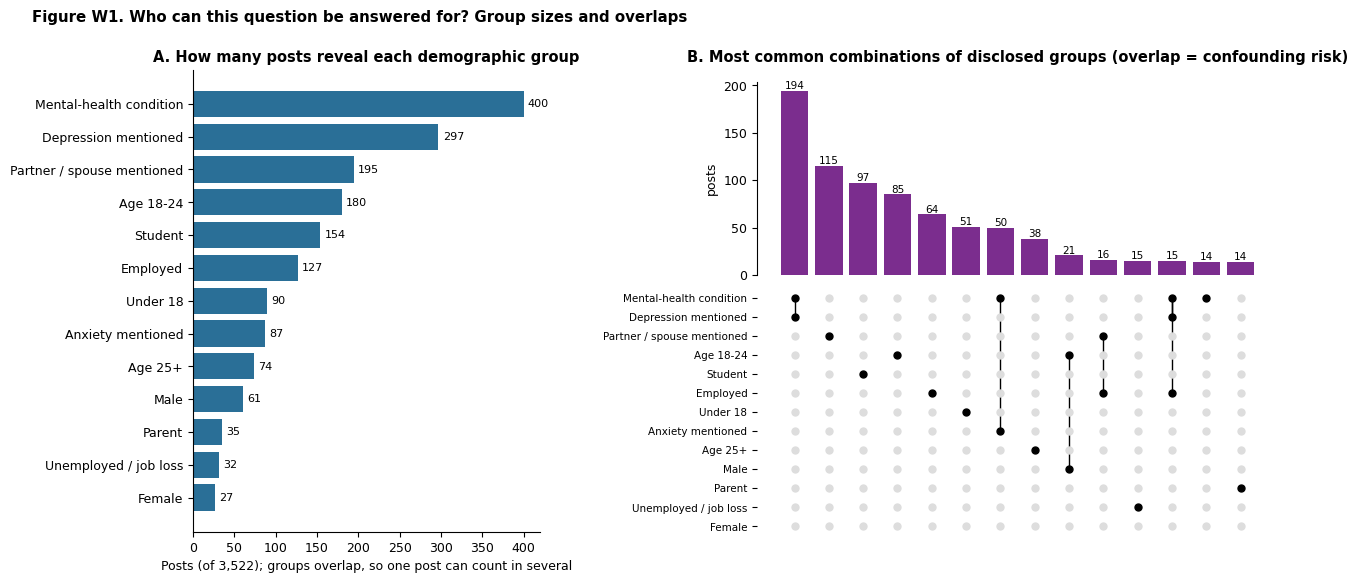

saved W01_groups_and_overlap.png


In [ ]:
# ------------------------------------------------------------------
# W01: WHO IS IN THE DATA & SUBGROUP OVERLAPS
# ------------------------------------------------------------------
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.5], wspace=0.5)

# --- Panel A: Group Frequencies ---
ax = fig.add_subplot(gs[0])
order = sorted(GR, key=lambda g: M[g].sum())
counts = [M[g].sum() for g in order]

ax.barh(order, counts, color="#2a6f97")
for i, g in enumerate(order):
    ax.text(M[g].sum() + 5, i, f"{M[g].sum():,}", va="center", fontsize=8)

ax.set_xlabel(f"Posts (of {N:,}); groups overlap, so one post can count in several")
ax.set_title("A. How many posts reveal each demographic group")

# --- Panel B: Most Common Combinations (UpSet-Style Map) ---
# Determine active groups per post and count frequent configurations
combo = S[GR].astype(int).apply(lambda r: tuple(c for c in GR if r[c]), axis=1)
cc = combo[combo.map(len) > 0].value_counts().head(14)

ax2 = fig.add_subplot(gs[1])
ax2.set_title("B. Most common combinations of disclosed groups (overlap = confounding risk)")
ax2.axis("off")

# Sub-gridspec layout for combination bar charts and connection matrix
sub = fig.add_gridspec(
    2, 1,
    height_ratios=[1, 1.3],
    hspace=0.05,
    left=gs[1].get_position(fig).x0,
    right=gs[1].get_position(fig).x1,
    top=0.86,
    bottom=0.1
)
axb = fig.add_subplot(sub[0])
axm = fig.add_subplot(sub[1], sharex=axb)

# Bar charts of configuration sizes
axb.bar(range(len(cc)), cc.values, color="#7b2d8e")
for i, v in enumerate(cc.values):
    axb.text(i, v + 2, f"{v:,}", ha="center", fontsize=7.5)

axb.set_ylabel("posts")
axb.set_xticks([])
axb.spines["bottom"].set_visible(False)

# Sort the vertical axes of combinations by overall population sizes
gl = sorted(GR, key=lambda g: -M[g].sum())

# Draw visual intersection lines and circular dots
for i, cmb in enumerate(cc.index):
    ys = [gl.index(c) for c in cmb]
    axm.plot([i] * len(ys), ys, "-", color="k", lw=1)
    for y_ in range(len(gl)):
        marker_color = "k" if y_ in ys else "#dddddd"
        axm.plot(i, y_, "o", color=marker_color, ms=5)

axm.set_yticks(range(len(gl)))
axm.set_yticklabels(gl, fontsize=7.5)
axm.set_xticks([])
axm.invert_yaxis()
axm.spines["bottom"].set_visible(False)
axm.spines["left"].set_visible(False)

# Save layout output
fig.suptitle(
    "Figure W1. Who can this question be answered for? Group sizes and overlaps",
    x=0.01,
    ha="left",
    fontweight="bold"
)
save(fig, "W01_groups_and_overlap.png")

### Figure W2 – Outcome mix by group
**What we get:** For each group, a 100% stacked bar of Neither / TBe only / PBu only / Both, sorted by the share with both, against all posts.

**Why we did it:** This is the direct answer to 'who is most affected by TBe, PBu and both': it shows the whole outcome distribution, not just one rate.

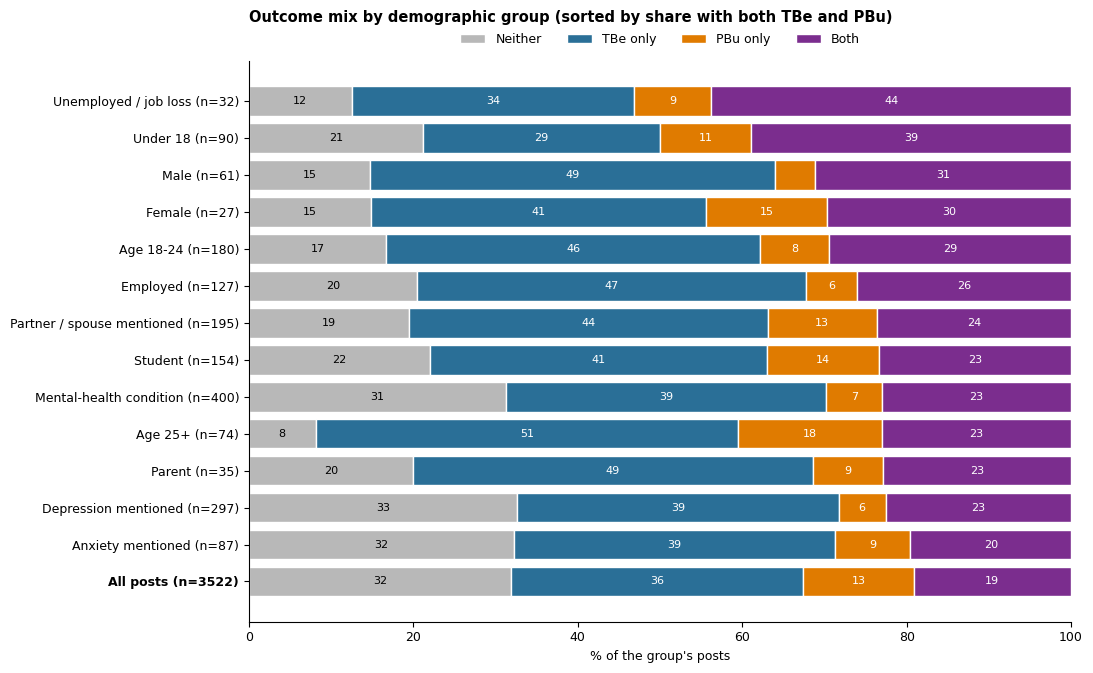

saved W02_outcome_mix_by_group.png


In [ ]:
# ------------------------------------------------------------------
# W02: STACKED OUTCOME MIX BY DEMOGRAPHIC GROUP
# ------------------------------------------------------------------
# Calculate percentages for each exclusive outcome class per demographic group
mix_data = {}
for g in GR:
    group_mask = M[g]
    mix_data[g] = {k: 100 * (out.cls[group_mask] == k).mean() for k in CL}

mix = pd.DataFrame(mix_data).T

# Include baseline mix across all posts
mix.loc["All posts"] = {k: 100 * (out.cls == k).mean() for k in CL}

# Keep track of subgroup sample sizes for vertical axis labels
ns = {g: int(M[g].sum()) for g in GR}
ns["All posts"] = N

# Sort ascendingly based on percentage of posts with both conditions
mix = mix.sort_values("Both")

fig, ax = plt.subplots(figsize=(11, 6.8))
left = np.zeros(len(mix))

# Draw segmented components for each outcome
for k in ["Neither", "TBe only", "PBu only", "Both"]:
    ax.barh(
        range(len(mix)),
        mix[k],
        left=left,
        color=CL[k],
        label=k,
        edgecolor="white"
    )
    # Place percentage numeric text values inside stacked segments if space permits
    for i, (v, l) in enumerate(zip(mix[k], left)):
        if v > 5:
            text_color = "white" if k != "Neither" else "black"
            ax.text(
                l + v / 2,
                i,
                f"{v:.0f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=8
            )
    left += mix[k].values

# Set tick positions and bold the 'All posts' baseline label
ax.set_yticks(range(len(mix)))
ax.set_yticklabels([f"{g} (n={ns[g]})" for g in mix.index])
all_posts_index = list(mix.index).index("All posts")
ax.get_yticklabels()[all_posts_index].set_fontweight("bold")

ax.set_xlabel("% of the group's posts")
ax.set_xlim(0, 100)

# Position the legend above the primary axes
ax.legend(
    ncol=4,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.07)
)

ax.set_title(
    "Outcome mix by demographic group (sorted by share with both TBe and PBu)",
    loc="left",
    pad=28
)

fig.tight_layout()
save(fig, "W02_outcome_mix_by_group.png")

### Figure W3 – Over- and under-representation (lift)
**What we get:** A heatmap of each group's % in every outcome; colour = how far it is above or below the overall rate; * = significant after FDR.

**Why we did it:** Lift puts rare and common outcomes on one scale, so we can see at a glance which group is over-represented in which outcome.

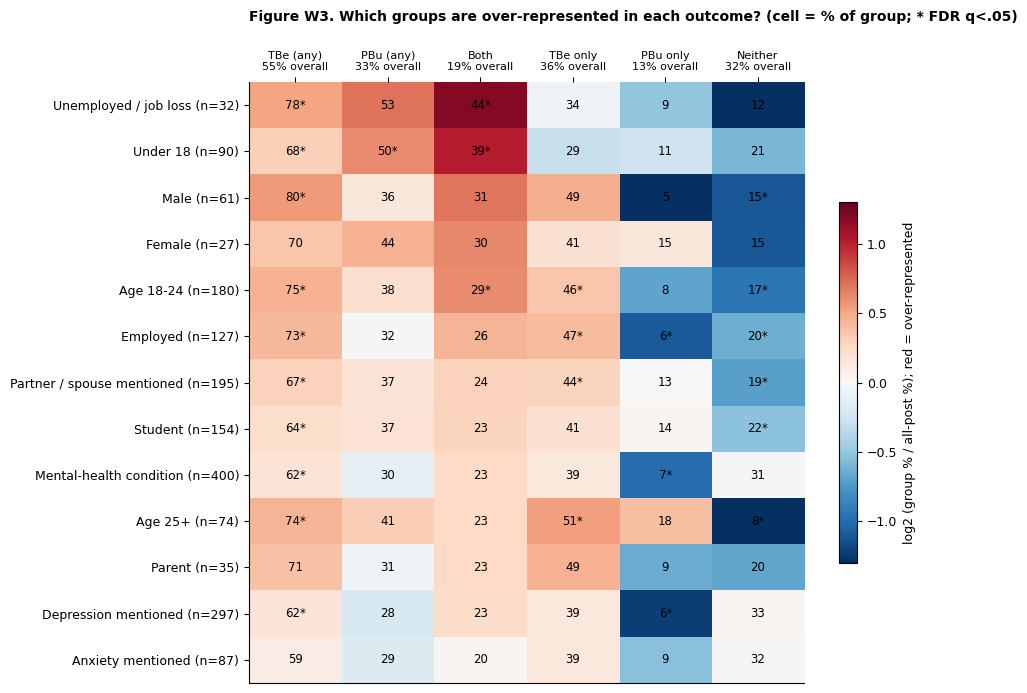

saved W03_lift_heatmap.png


In [ ]:
# ------------------------------------------------------------------
# W03: LIFT HEATMAP BY GROUP AND OUTCOME
# ------------------------------------------------------------------
# Select target columns and pivot master statistics for the heatmap
OCH = ["TBe (any)", "PBu (any)", "Both", "TBe only", "PBu only", "Neither"]

L = T.pivot(index="group", columns="outcome", values="lift")[OCH]
P = T.pivot(index="group", columns="outcome", values="pct")[OCH]
Q = T.pivot(index="group", columns="outcome", values="q")[OCH]

# Sort group index descendingly based on 'Both' outcome's lift ratio
ordg = L["Both"].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9.6, 7))

# Map log2 of lift values into colors (Red represents over-representation)
im = ax.imshow(
    np.log2(L.loc[ordg].values),
    cmap="RdBu_r",
    vmin=-1.3,
    vmax=1.3,
    aspect="auto"
)

# Configure tick formats and place label coordinates above
ax.set_xticks(range(6))
ax.set_xticklabels(
    [f"{o}\n{100*base[o]:.0f}% overall" for o in OCH],
    fontsize=8
)
ax.xaxis.tick_top()

ax.set_yticks(range(len(ordg)))
ax.set_yticklabels([f"{g} (n={ns[g]})" for g in ordg])

# Add numeric percent values inside cell labels and mark FDR significant cells
for i, g in enumerate(ordg):
    for j, o in enumerate(OCH):
        is_sig = Q.loc[g, o] < 0.05
        star = "*" if is_sig else ""
        val_text = f"{P.loc[g, o]:.0f}{star}"
        ax.text(
            j,
            i,
            val_text,
            ha="center",
            va="center",
            fontsize=8.5
        )

plt.colorbar(
    im,
    shrink=0.6,
    label="log2 (group % / all-post %); red = over-represented"
)

ax.set_title(
    "Figure W3. Which groups are over-represented in each outcome? (cell = % of group; * FDR q<.05)",
    loc="left",
    pad=44,
    fontsize=10
)

fig.tight_layout()
save(fig, "W03_lift_heatmap.png")

### Figure W4 – Ranked rates with uncertainty and shrinkage
**What we get:** For TBe, PBu and Both: each group's rate with a Wilson CI (blue) and an empirical-Bayes shrunken estimate (orange diamond).

**Why we did it:** Small groups can top a raw ranking by chance. Shrinkage shows which rankings survive when small samples are pulled toward the average.

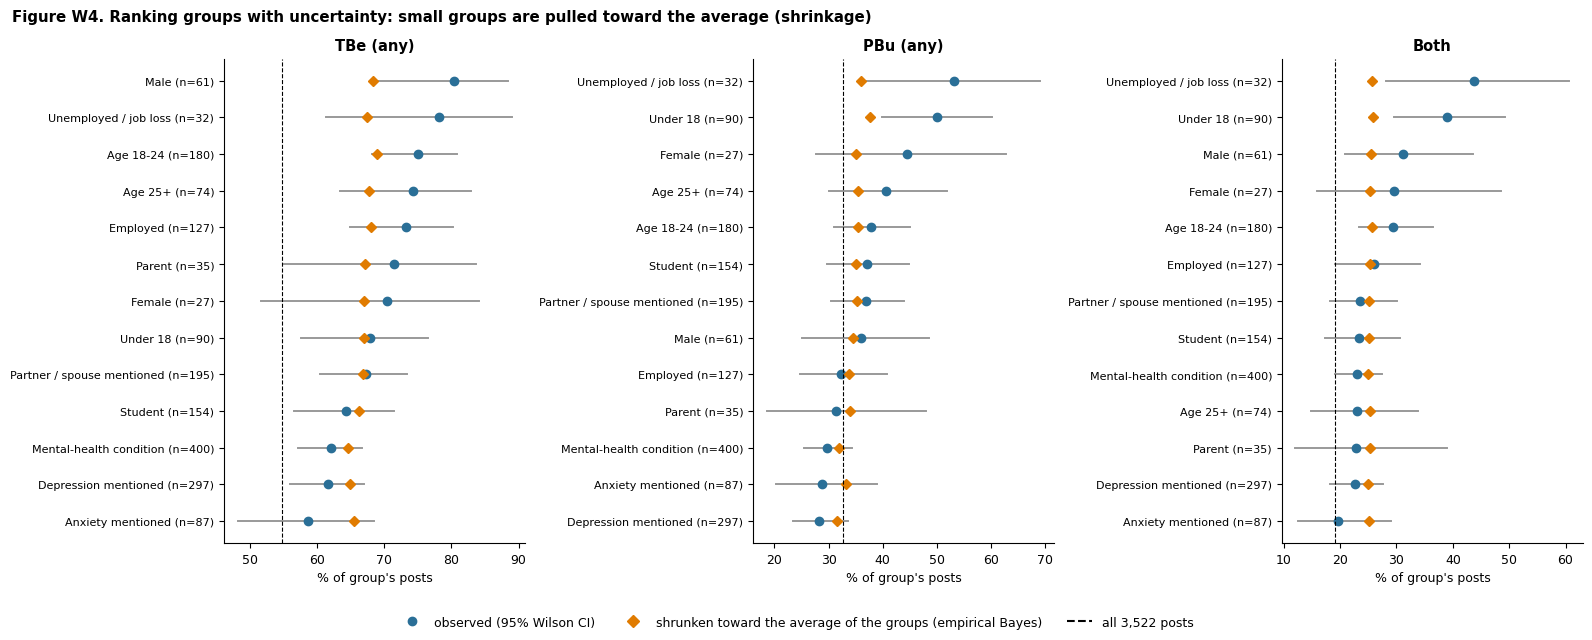

saved W04_ranked_rates_shrinkage.png


In [ ]:
# ------------------------------------------------------------------
# W04: CATERPILLAR PLOT WITH BAYESIAN SHRINKAGE
# ------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(16, 6.4), sharey=False)

for ax, o in zip(axs, OC3):
    # Sort subgroups by their observed rate
    s = T[T.outcome == o].sort_values("pct").reset_index(drop=True)

    # Plot each group's observed rate, confidence interval, and shrunken rate
    for i, r in s.iterrows():
        lo, hi = wil(r.k, r.n)

        # Plot 95% Wilson confidence interval line
        ax.plot([lo, hi], [i, i], color="#999999", lw=1.4)

        # Plot observed rate as a blue circle
        ax.plot(r.pct, i, "o", color="#2a6f97", ms=6)

        # Plot Empirical Bayes shrunken estimate as an orange diamond
        ax.plot(r.shrunk, i, "D", color="#e07b00", ms=5)

    # Draw a vertical dashed line representing the overall baseline rate
    ax.axvline(100 * base[o], ls="--", color="k", lw=0.8)

    # Configure tick marks and titles
    ax.set_yticks(range(len(s)))
    ax.set_yticklabels([f"{r.group} (n={r.n})" for r in s.itertuples()], fontsize=8)
    ax.set_xlabel("% of group's posts")
    ax.set_title(o)

# Add representative legend elements to the left panel for cleaner mapping
axs[0].plot([], [], "o", color="#2a6f97", label="observed (95% Wilson CI)")
axs[0].plot([], [], "D", color="#e07b00", label="shrunken toward the average of the groups (empirical Bayes)")
axs[0].plot([], [], "k--", label="all 3,522 posts")

fig.legend(
    *axs[0].get_legend_handles_labels(),
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=9
)

fig.suptitle(
    "Figure W4. Ranking groups with uncertainty: small groups are pulled toward the average (shrinkage)",
    x=0.01,
    ha="left",
    fontweight="bold"
)

# Adjust layout and save visualization output
fig.tight_layout(rect=[0, 0.06, 1, 1])
save(fig, "W04_ranked_rates_shrinkage.png")

### Figure W5 – Effect sizes: odds ratios by outcome
**What we get:** Odds ratios (log scale) with 95% CIs for TBe only, PBu only and Both, each against all other posts.

**Why we did it:** Odds ratios compare the exclusive outcome classes and show effect size and uncertainty together; filled points survive FDR correction.

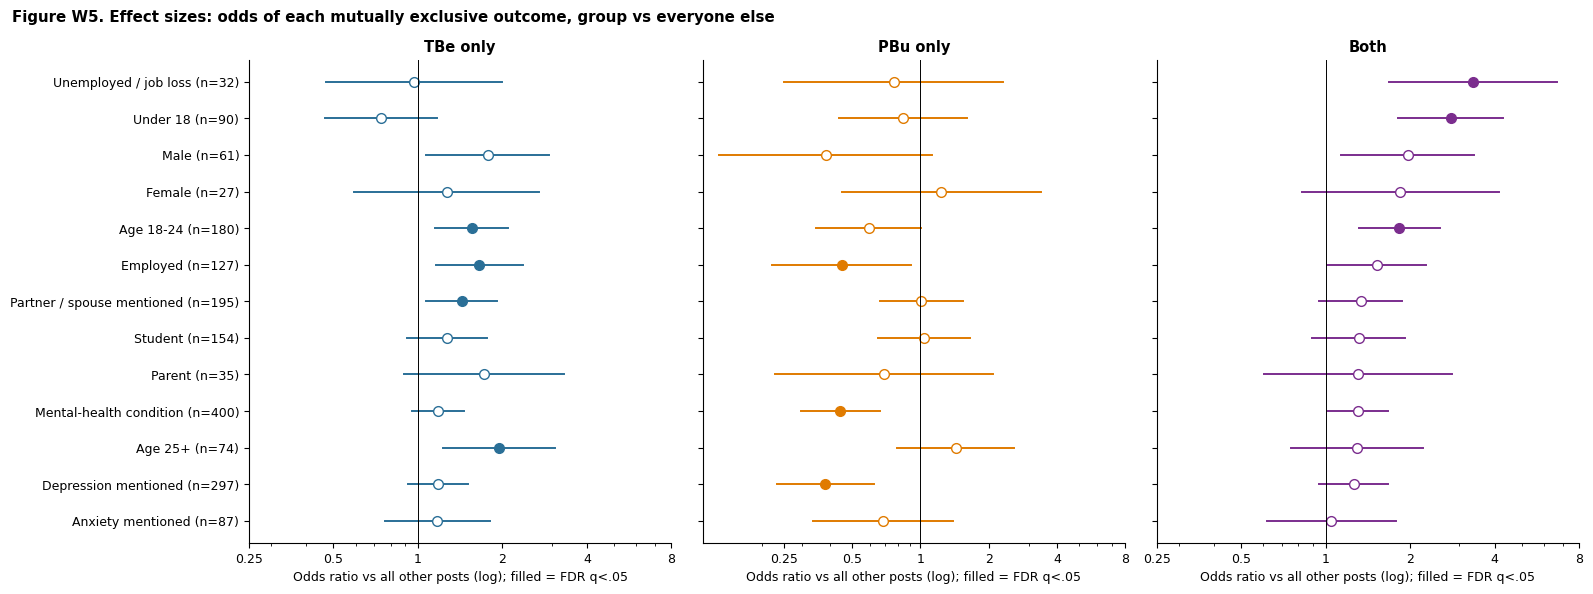

saved W05_odds_ratio_forest.png


In [ ]:
# ------------------------------------------------------------------
# W05: EFFECT SIZES (ODDS RATIOS BY MUTUALLY EXCLUSIVE OUTCOME)
# ------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

# Sort the vertical axes of the forest plots by odds ratio for the 'Both' outcome
orderf = T[T.outcome == "Both"].sort_values("OR").group.tolist()

# Define target categories and map each to its respective color indicator
targets = ["TBe only", "PBu only", "Both"]
colors = [CL["TBe only"], CL["PBu only"], CL["Both"]]

for ax, outcome_class, col in zip(axs, targets, colors):
    # Extract and align metrics for the sorted demographic categories
    sub_df = T[T.outcome == outcome_class].set_index("group").loc[orderf]

    for i, (g, r) in enumerate(sub_df.iterrows()):
        # Plot the odds ratio 95% confidence interval horizontal range line
        ax.plot([r.lo, r.hi], [i, i], color=col, lw=1.4)

        # Use a filled circle marker if the finding is FDR-significant (q < 0.05),
        # otherwise render a hollow marker
        marker_fill_color = col if r.q < 0.05 else "white"
        ax.plot(
            r.OR,
            i,
            "o",
            color=marker_fill_color,
            mec=col,
            ms=7
        )

    # Draw reference baseline line (Odds Ratio = 1.0 representing zero effect)
    ax.axvline(1.0, color="k", lw=0.7)

    # Configure logarithmic x-axis scaling and tick spacing
    ax.set_xscale("log")
    ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
    ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8"])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

    # Axis labels
    ax.set_title(outcome_class)
    ax.set_xlabel("Odds ratio vs all other posts (log); filled = FDR q<.05")

# Label the vertical axes on the leftmost subplot with demographic groups and sizes
axs[0].set_yticks(range(len(orderf)))
axs[0].set_yticklabels([f"{g} (n={ns[g]})" for g in orderf])

fig.suptitle(
    "Figure W5. Effect sizes: odds of each mutually exclusive outcome, group vs everyone else",
    x=0.01,
    ha="left",
    fontweight="bold"
)

fig.tight_layout()
save(fig, "W05_odds_ratio_forest.png")

### Figure W6 – Multinomial logistic regression (adjusted)
**What we get:** Adjusted odds ratios of being TBe-only, PBu-only or Both rather than Neither, for all groups together (A) and with age added in the age-known subset (B); bootstrap CIs.

**Why we did it:** Groups overlap, so a single-group comparison can mislead. A multi-class model shows which groups stay linked to each outcome when the others are held constant.

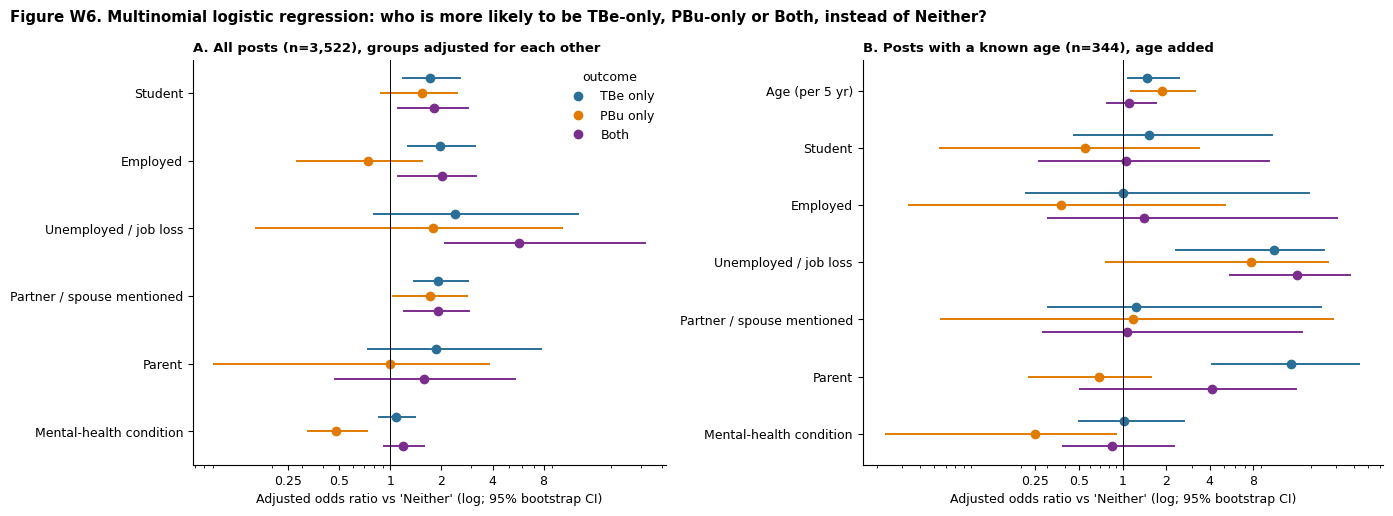

saved W06_multinomial_logistic.png


In [ ]:
# ------------------------------------------------------------------
# W06: MULTINOMIAL LOGISTIC REGRESSION (ADJUSTED ODDS RATIOS)
# ------------------------------------------------------------------
# Define the list of primary demographic predictor columns
PRED = [
    "Student",
    "Employed",
    "Unemployed / job loss",
    "Partner / spouse mentioned",
    "Parent",
    "Mental-health condition"
]

def multinom_or(Xm, y, nboot=300, seed=3):
    """Fit multinomial logistic models and calculate odds ratios with bootstrapped CIs."""
    rng = np.random.default_rng(seed)
    classes = ["Neither", "TBe only", "PBu only", "Both"]

    def fit(idx):
        # Fit a robust regularized logistic regression model
        m = LogisticRegression(C=10, max_iter=500).fit(Xm[idx], y[idx])
        cl = list(m.classes_)
        ref = cl.index("Neither")

        # Return odds ratio exponentiated coefficients relative to 'Neither' reference
        return {
            c: np.exp(m.coef_[cl.index(c)] - m.coef_[ref])
            for c in classes[1:]
        }

    # Generate baseline coefficients and gather bootstrap replicates
    base_estimates = fit(np.arange(len(y)))
    bootstrap_results = [
        fit(rng.integers(0, len(y), len(y)))
        for _ in range(nboot)
    ]

    # Calculate 95% bootstrap confidence intervals for each class
    intervals = {}
    for c in base_estimates:
        est = base_estimates[c]
        low_ci = np.percentile([b[c] for b in bootstrap_results], 2.5, axis=0)
        high_ci = np.percentile([b[c] for b in bootstrap_results], 97.5, axis=0)
        intervals[c] = (est, low_ci, high_ci)

    return intervals

# --- 1. Compute models for Panel A and Panel B ---
y4 = out.cls.values
resA = multinom_or(S[PRED].values.astype(float), y4)

# Subset for posts with explicit self-disclosed ages
ak = d.age_num.notna().values
XB = np.c_[
    (d.age_num.values[ak] - 20) / 5,  # Normalize numeric age around 20 (scaled by 5 years)
    S.loc[ak, PRED].values
]
resB = multinom_or(XB, y4[ak])
namesB = ["Age (per 5 yr)"] + PRED

# --- 2. Plotting setup ---
fig, axs = plt.subplots(
    1, 2,
    figsize=(14, 5.2),
    gridspec_kw={"width_ratios": [1, 1.1]}
)

panels = [
    (axs[0], resA, PRED, f"A. All posts (n={N:,}), groups adjusted for each other"),
    (axs[1], resB, namesB, f"B. Posts with a known age (n={ak.sum()}), age added")
]

# Draw vertical forest plots for both adjusted subsets
for ax, results, names, title in panels:
    # Map outcomes to slight vertical offsets to prevent visual overlap
    offsets = [("TBe only", 0.22), ("PBu only", 0.0), ("Both", -0.22)]

    for outcome_class, off in offsets:
        o_estimates, lo, hi = results[outcome_class]

        for i in range(len(names)):
            y_coord = len(names) - 1 - i + off
            # Draw bootstrap 95% confidence interval horizontal bar
            ax.plot([lo[i], hi[i]], [y_coord, y_coord], color=CL[outcome_class], lw=1.4)

            # Place estimate point marker (only attach label on first pass for legend)
            label = outcome_class if i == 0 else None
            ax.plot(o_estimates[i], y_coord, "o", color=CL[outcome_class], ms=6, label=label)

    # Reference line at odds ratio = 1.0 (no effect)
    ax.axvline(1.0, color="k", lw=0.7)

    # Coordinate limits, logarithmic scale, and labels
    ax.set_xscale("log")
    ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
    ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8"])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names[::-1])

    ax.set_title(title, loc="left", fontsize=9.5)
    ax.set_xlabel("Adjusted odds ratio vs 'Neither' (log; 95% bootstrap CI)")

# Position the general legend on the left panel
axs[0].legend(frameon=False, title="outcome")

fig.suptitle(
    "Figure W6. Multinomial logistic regression: who is more likely to be TBe-only, PBu-only or Both, instead of Neither?",
    x=0.01,
    ha="left",
    fontweight="bold"
)

fig.tight_layout()
save(fig, "W06_multinomial_logistic.png")

### Figure W7 – Decision trees
**What we get:** Depth-3 trees for TBe, PBu, Both, and Both in the age-known subset, with cross-validated AUC in each title.

**Why we did it:** Trees find the splits that best separate affected writers and show the interactions in a way that is easy to read. The AUCs near 0.5 show how little demographics separate the outcomes.

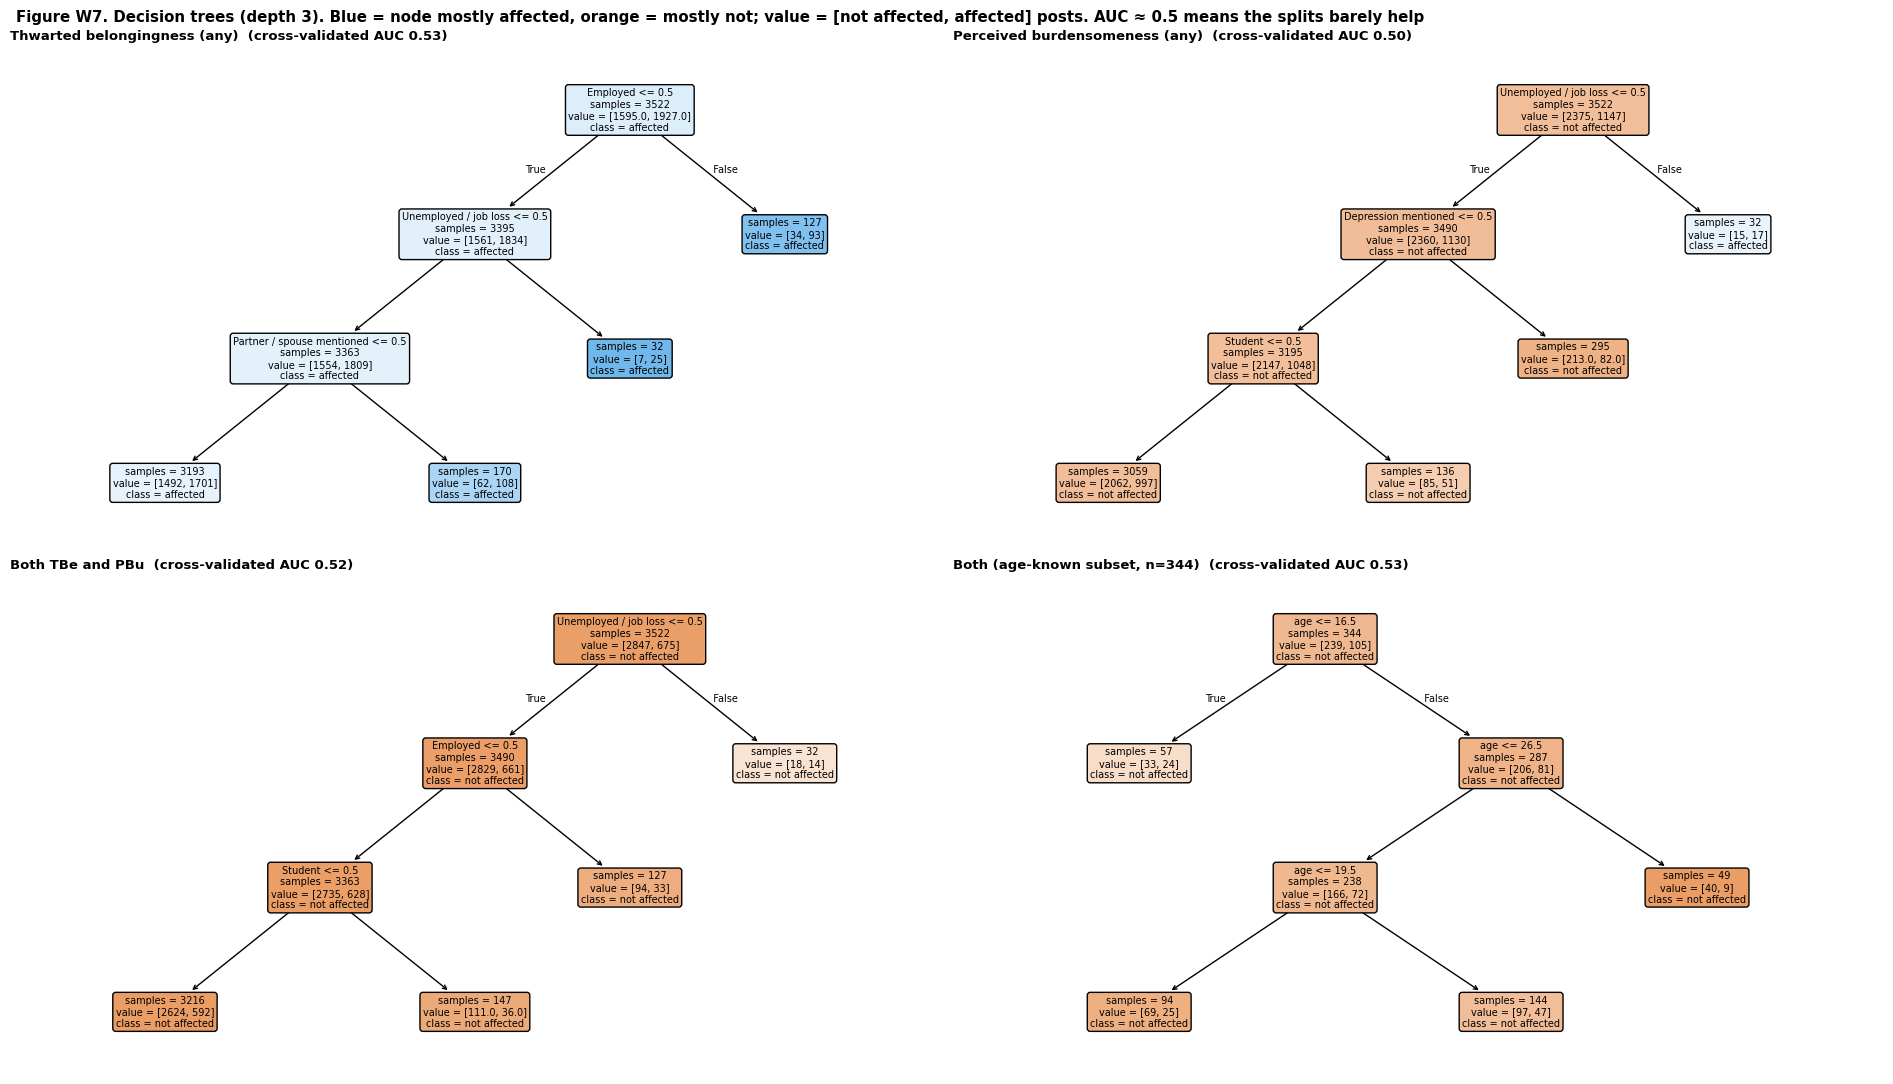

saved W07_decision_trees.png


In [ ]:
# ------------------------------------------------------------------
# W07: DECISION TREES
# ------------------------------------------------------------------
# Define variables for predictors, incorporating specific clinical conditions
PF = PRED + ["Depression mentioned", "Anxiety mentioned"]

def tree_panel(ax, Xm, y, names, title):
    """Fit a simple decision tree model, calculate CV AUC, and plot the node map."""
    # Initialize decision tree classifier
    dt_config = {
        "max_depth": 3,
        "min_samples_leaf": 30,
        "random_state": 0
    }

    dt = DecisionTreeClassifier(**dt_config).fit(Xm, y)

    # Evaluate predictive strength using cross-validated ROC AUC metrics
    cv_strategy = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=5,
        random_state=0
    )

    cv_scores = cross_val_score(
        DecisionTreeClassifier(**dt_config),
        Xm, y,
        cv=cv_strategy,
        scoring="roc_auc"
    )
    auc_mean = cv_scores.mean()

    # Plot the structural decision map
    plot_tree(
        dt,
        feature_names=names,
        class_names=["not affected", "affected"],
        filled=True,
        impurity=False,
        rounded=True,
        fontsize=7,
        ax=ax,
        proportion=False,
        precision=2
    )

    ax.set_title(f"{title}  (cross-validated AUC {auc_mean:.2f})", loc="left", fontsize=9.5)

# Prepare figure grids and predictor inputs
fig, axs = plt.subplots(2, 2, figsize=(19, 11))
Xf = S[PF].values

# --- Populate Decision Trees Panels ---
# Panel 1: Thwarted Belongingness
tree_panel(
    axs[0, 0],
    Xf,
    OUTC["TBe (any)"].astype(int),
    PF,
    "Thwarted belongingness (any)"
)

# Panel 2: Perceived Burdensomeness
tree_panel(
    axs[0, 1],
    Xf,
    OUTC["PBu (any)"].astype(int),
    PF,
    "Perceived burdensomeness (any)"
)

# Panel 3: Both Targets
tree_panel(
    axs[1, 0],
    Xf,
    OUTC["Both"].astype(int),
    PF,
    "Both TBe and PBu"
)

# Panel 4: Both Targets for the Age-Known Subpopulation
XB_tree = np.c_[d.age_num.values[ak], S.loc[ak, PF].values]
tree_panel(
    axs[1, 1],
    XB_tree,
    OUTC["Both"][ak].astype(int),
    ["age"] + PF,
    f"Both (age-known subset, n={ak.sum()})"
)

fig.suptitle(
    "Figure W7. Decision trees (depth 3). Blue = node mostly affected, orange = mostly not; value = [not affected, affected] posts. AUC ≈ 0.5 means the splits barely help",
    x=0.01,
    ha="left",
    fontweight="bold"
)

fig.tight_layout()
save(fig, "W07_decision_trees.png")

### Figure W8 – Predictive power and feature importance
**What we get:** A: cross-validated AUC of logistic regression, random forest and gradient boosting. B: permutation importance (AUC drop) for each group.

**Why we did it:** Statistical significance is not the same as usefulness. If demographics predict poorly, they should not be used to single out individuals, even when group rates differ.

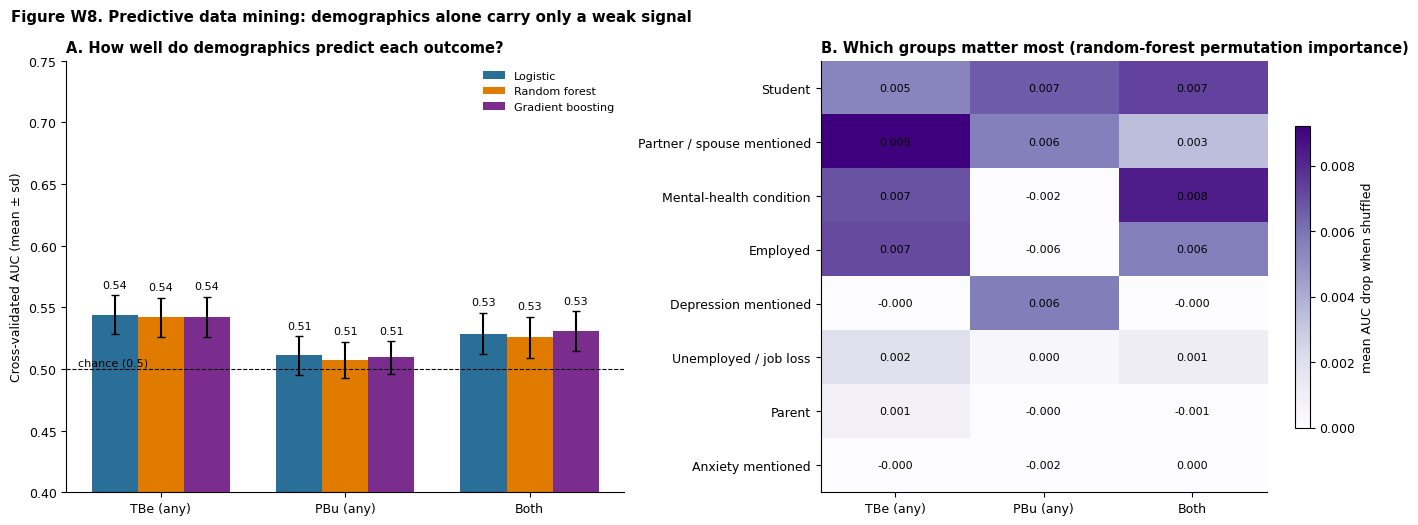

saved W08_prediction_and_importance.png


In [ ]:
# ------------------------------------------------------------------
# W08: PREDICTIVE MODELS & FEATURE IMPORTANCE
# ------------------------------------------------------------------
def calculate_cv_auc(model, X_matrix, y_true, repeats=5):
    """Compute cross-validated ROC AUC scores using repeated stratified folds."""
    cv_strategy = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=repeats,
        random_state=1
    )
    return cross_val_score(
        model,
        X_matrix,
        y_true,
        cv=cv_strategy,
        scoring="roc_auc"
    )

# Configure predictive baseline models
model_library = {
    "Logistic": lambda: LogisticRegression(C=1, max_iter=500),
    "Random forest": lambda: RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        random_state=0,
        n_jobs=2
    ),
    "Gradient boosting": lambda: GradientBoostingClassifier(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.05,
        random_state=0
    )
}

# 1. Evaluate Model Performance Metrics
auc_results = {}
for outcome in OC3:
    y_target = OUTC[outcome].astype(int)
    for model_name, model_fn in model_library.items():
        auc_results[(outcome, model_name)] = calculate_cv_auc(
            model_fn(),
            Xf,
            y_target,
            repeats=3
        )

# 2. Evaluate Permutation Importance via Stratified K-Folds
importance_df = pd.DataFrame(0.0, index=PF, columns=OC3)
for outcome in OC3:
    y_target = OUTC[outcome].astype(int)
    kf_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

    for train_idx, test_idx in kf_split.split(Xf, y_target):
        rf_model = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=0,
            n_jobs=2
        ).fit(Xf[train_idx], y_target[train_idx])

        perm_importance = permutation_importance(
            rf_model,
            Xf[test_idx],
            y_target[test_idx],
            scoring="roc_auc",
            n_repeats=10,
            random_state=0
        )
        importance_df[outcome] += perm_importance.importances_mean / 5

# 3. Visualization Setup
fig, axs = plt.subplots(1, 2, figsize=(14, 5.3), gridspec_kw={"width_ratios": [1, 1]})
bar_width = 0.25

# --- Panel A: Cross-Validated AUC Strengths ---
for idx, model_name in enumerate(model_library):
    mean_scores = [auc_results[(o, model_name)].mean() for o in OC3]
    std_devs = [auc_results[(o, model_name)].std() for o in OC3]

    x_positions = np.arange(len(OC3)) + (idx - 1) * bar_width
    axs[0].bar(
        x_positions,
        mean_scores,
        bar_width,
        yerr=std_devs,
        color=["#2a6f97", "#e07b00", "#7b2d8e"][idx],
        label=model_name,
        capsize=3
    )
    for pos_idx, score in enumerate(mean_scores):
        y_label_pos = score + std_devs[pos_idx] + 0.006
        axs[0].text(
            x_positions[pos_idx],
            y_label_pos,
            f"{score:.2f}",
            ha="center",
            fontsize=8
        )

axs[0].axvline(x=-0.5, color="none")  # Visual boundary padding
axs[0].axhline(0.5, ls="--", color="k", lw=0.8)
axs[0].text(-0.45, 0.503, "chance (0.5)", fontsize=8, ha="left")
axs[0].set_xticks(range(3))
axs[0].set_xticklabels(OC3)
axs[0].set_ylim(0.4, 0.75)
axs[0].set_ylabel("Cross-validated AUC (mean ± sd)")
axs[0].legend(frameon=False, fontsize=8)
axs[0].set_title("A. How well do demographics predict each outcome?", loc="left")

# --- Panel B: Random Forest Feature Importance ---
sorted_features = importance_df.mean(axis=1).sort_values(ascending=False).index
sorted_values = importance_df.loc[sorted_features].values

im = axs[1].imshow(
    sorted_values,
    cmap="Purples",
    aspect="auto",
    vmin=0
)

axs[1].set_xticks(range(3))
axs[1].set_xticklabels(OC3)
axs[1].set_yticks(range(len(sorted_features)))
axs[1].set_yticklabels(sorted_features)

for i, feature_name in enumerate(sorted_features):
    for j, outcome in enumerate(OC3):
        score_val = importance_df.loc[feature_name, outcome]
        axs[1].text(
            j,
            i,
            f"{score_val:.3f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(
    im,
    ax=axs[1],
    shrink=0.7,
    label="mean AUC drop when shuffled"
)
axs[1].set_title(
    "B. Which groups matter most (random-forest permutation importance)",
    loc="left"
)

fig.suptitle(
    "Figure W8. Predictive data mining: demographics alone carry only a weak signal",
    x=0.01,
    ha="left",
    fontweight="bold"
)
fig.tight_layout()
save(fig, "W08_prediction_and_importance.png")

### Figure W9 – Subgroup discovery
**What we get:** Subgroups (up to three traits combined, ≥25 posts) with the highest outcome rates for TBe, PBu and Both, found with Apriori.

**Why we did it:** Data mining can reveal combinations (e.g. 18-24 and a mental-health condition) that single-group analysis misses; FDR and minimum size guard against chance findings.

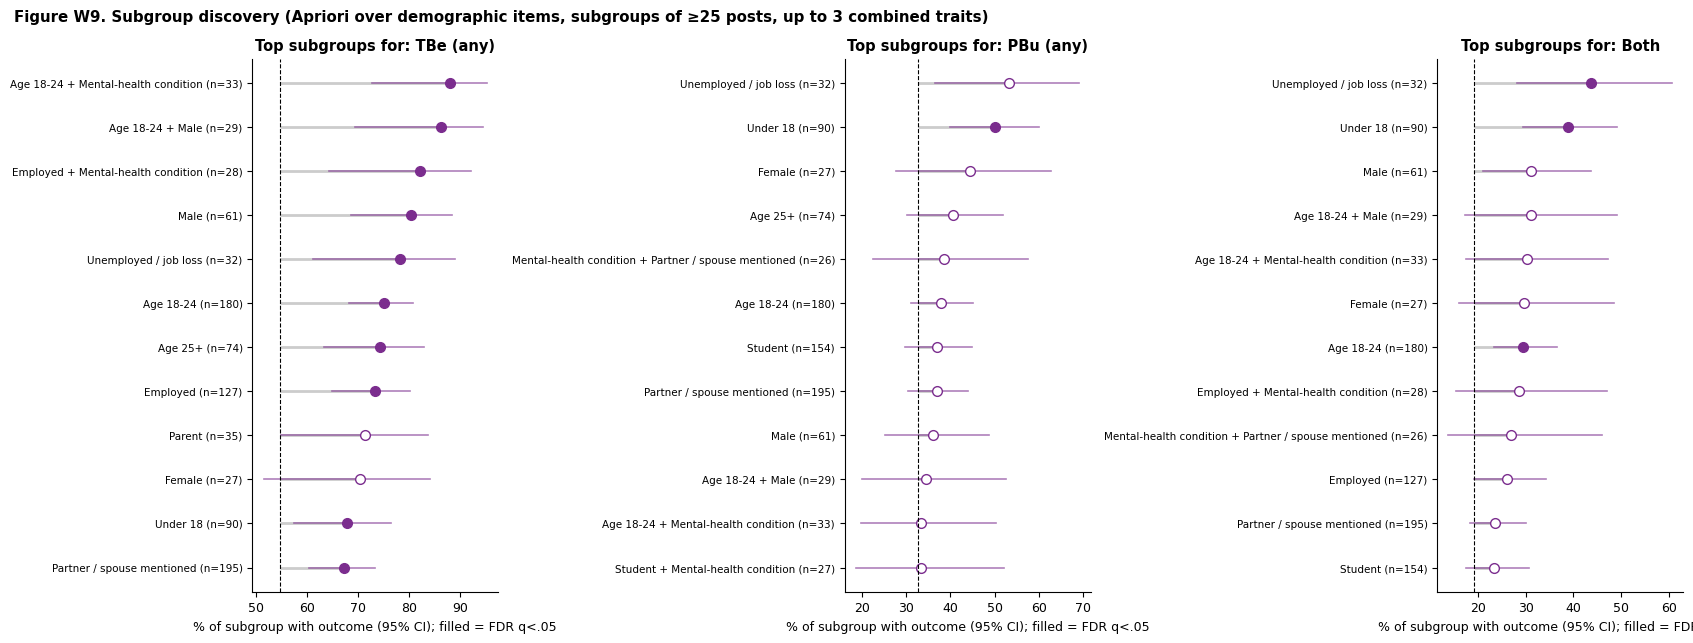

saved W09_subgroup_discovery.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ------------------------------------------------------------------
# W09: SUBGROUP DISCOVERY (APRIORI)
# ------------------------------------------------------------------
# Extract boolean dataframe and find frequent itemsets
boolean_df = S[GR].astype(bool)
frequent_itemsets = apriori(
    boolean_df,
    min_support=25 / N,
    max_len=3,
    use_colnames=True
)

subgroups_list = []
for itemset in frequent_itemsets["itemsets"]:
    itemset_tuple = tuple(itemset)

    # Intersect the logical index arrays for all groups in the itemset
    group_mask = np.logical_and.reduce([M[g] for g in itemset_tuple])
    subgroup_size = int(group_mask.sum())

    if subgroup_size < 25:
        continue

    for outcome in OC3:
        outcome_hits = int((group_mask & OUTC[outcome]).sum())

        # Define confusion matrix categories for Fisher Exact test
        a = outcome_hits
        b = subgroup_size - outcome_hits
        c = int((~group_mask & OUTC[outcome]).sum())
        d_val = int((~group_mask & ~OUTC[outcome]).sum())

        lo, hi = wil(outcome_hits, subgroup_size)
        p_value = fisher_exact([[a, b], [c, d_val]])[1]

        subgroups_list.append({
            "sub": " + ".join(itemset_tuple),
            "size": len(itemset_tuple),
            "n": subgroup_size,
            "outcome": outcome,
            "k": outcome_hits,
            "pct": 100 * outcome_hits / subgroup_size,
            "lo": lo,
            "hi": hi,
            "lift": (outcome_hits / subgroup_size) / base[outcome],
            "p": p_value
        })

# Construct statistical DataFrame and correct for false discovery rate
SG = pd.DataFrame(subgroups_list)
SG["q"] = multipletests(SG.p, method="fdr_bh")[1]

# Set up plots for each outcome
fig, axs = plt.subplots(1, 3, figsize=(17, 6.5))

for ax, outcome in zip(axs, OC3):
    # Filter subgroups that are over-represented and display the top 12
    top_subgroups = (
        SG[(SG.outcome == outcome) & (SG.lift > 1)]
        .sort_values("lift", ascending=False)
        .head(12)
        .iloc[::-1]
    )

    # Draw horizontal baseline connections
    ax.hlines(
        range(len(top_subgroups)),
        100 * base[outcome],
        top_subgroups.pct,
        color="#cccccc",
        lw=2
    )

    # Plot confidence interval lines and point markers
    for idx, row in enumerate(top_subgroups.itertuples()):
        ax.plot(
            [row.lo, row.hi],
            [idx, idx],
            color="#7b2d8e",
            lw=1.2,
            alpha=0.6
        )

        # Use filled markers if the FDR q-value is statistically significant
        marker_fill = "#7b2d8e" if row.q < 0.05 else "white"
        ax.plot(
            row.pct,
            idx,
            "o",
            color=marker_fill,
            mec="#7b2d8e",
            ms=7
        )

    ax.axvline(100 * base[outcome], ls="--", color="k", lw=0.8)
    ax.set_yticks(range(len(top_subgroups)))

    label_texts = [f"{row.sub} (n={row.n})" for row in top_subgroups.itertuples()]
    ax.set_yticklabels(label_texts, fontsize=7.5)
    ax.set_xlabel("% of subgroup with outcome (95% CI); filled = FDR q<.05")
    ax.set_title(f"Top subgroups for: {outcome}")

fig.suptitle(
    "Figure W9. Subgroup discovery (Apriori over demographic items, subgroups of ≥25 posts, up to 3 combined traits)",
    x=0.01,
    ha="left",
    fontweight="bold"
)
fig.tight_layout()
save(fig, "W09_subgroup_discovery.png")

### Figure W10 – Intersections of two traits
**What we get:** Heatmaps of outcome rate when two traits occur together (diagonal = single trait); small cells hidden.

**Why we did it:** Shows where traits reinforce each other, such as employed and partner mentioned, and where sample sizes are too small to say.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

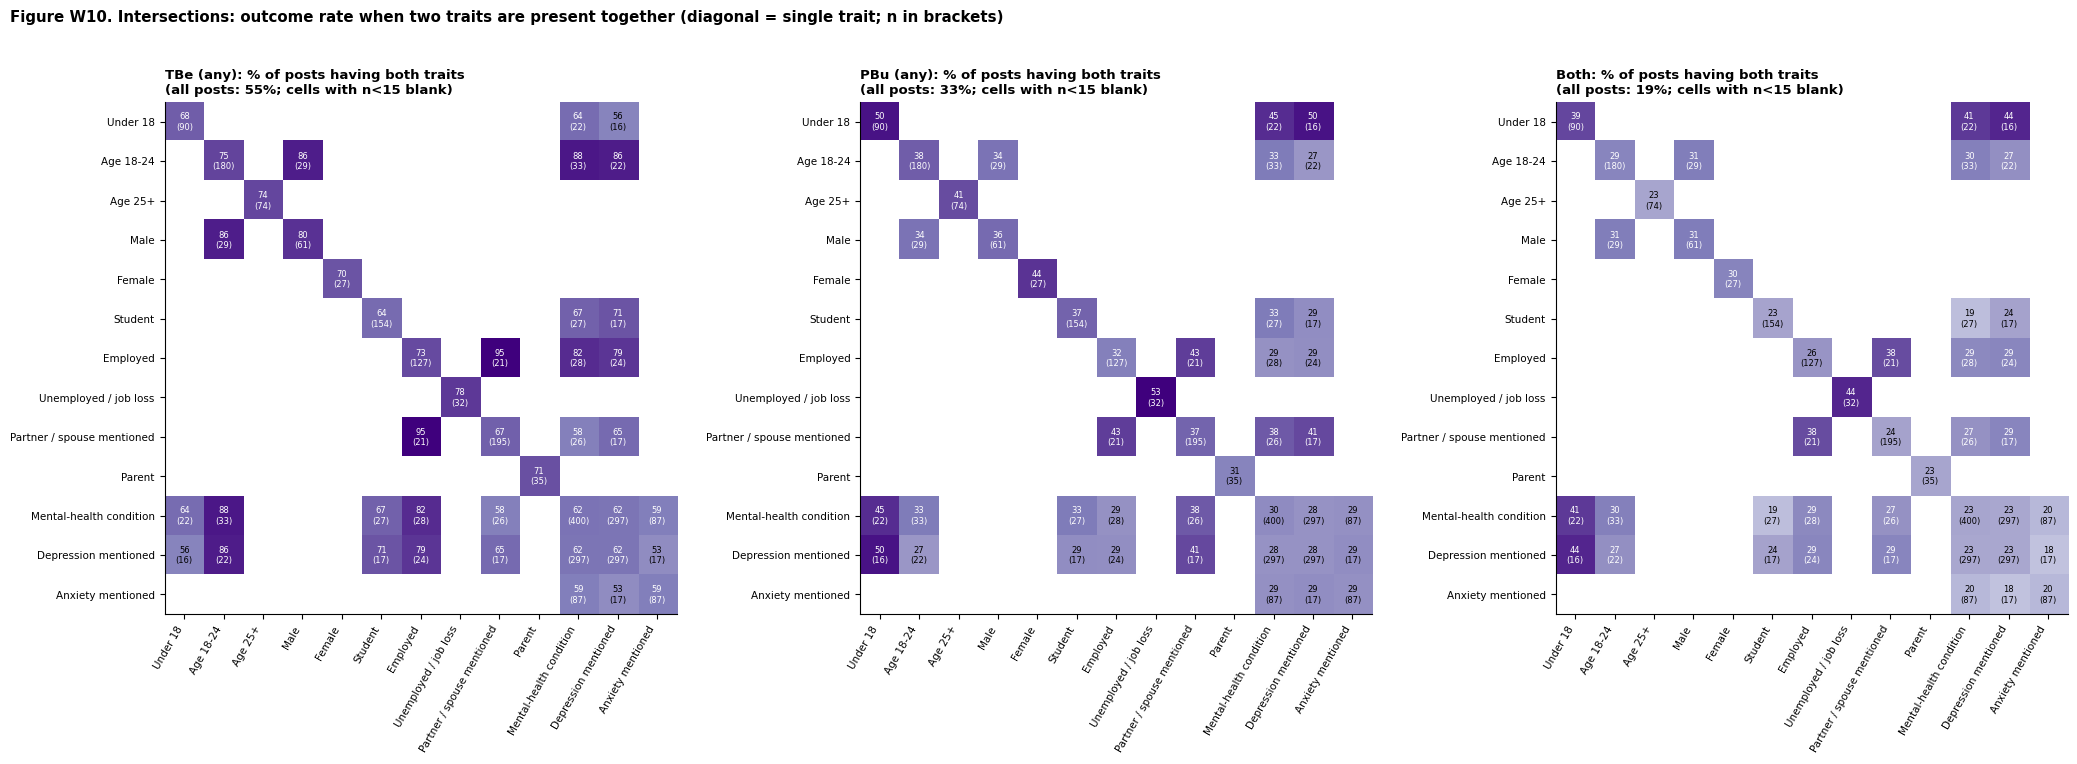

saved W10_intersection_heatmaps.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ---------- W10 intersection heatmaps ----------
fig, axs = plt.subplots(1, 3, figsize=(21, 7.2)); gl = GR
for ax, o in zip(axs, OC3):
    Mx = np.full((len(gl), len(gl)), np.nan); Nn = np.zeros((len(gl), len(gl)), int)
    for i, a in enumerate(gl):
        for j, b in enumerate(gl):
            m = M[a] & M[b]; Nn[i, j] = m.sum()
            if m.sum() >= 15: Mx[i, j] = 100 * OUTC[o][m].mean()
    im = ax.imshow(Mx, cmap="Purples", vmin=0, vmax=np.nanmax(Mx) if o != "Both" else 50); ax.set_xticks(range(len(gl))); ax.set_xticklabels(gl, rotation=60, ha="right", fontsize=7.5); ax.set_yticks(range(len(gl))); ax.set_yticklabels(gl, fontsize=7.5)
    for i in range(len(gl)):
        for j in range(len(gl)):
            if not np.isnan(Mx[i, j]): ax.text(j, i, f"{Mx[i, j]:.0f}\n({Nn[i, j]})", ha="center", va="center", fontsize=6, color="white" if Mx[i, j] > np.nanmax(Mx) * .6 else "k")
    ax.set_title(f"{o}: % of posts having both traits\n(all posts: {100*base[o]:.0f}%; cells with n<15 blank)", loc="left", fontsize=9.5)
fig.suptitle("Figure W10. Intersections: outcome rate when two traits are present together (diagonal = single trait; n in brackets)", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(rect=[0, 0, 1, .93]); save(fig, "W10_intersection_heatmaps.png")

### Figure W11 – Age group within life context
**What we get:** Outcome rates for under 18 / 18-24 / 25+ within student, employed, partner and mental-health contexts.

**Why we did it:** Separates age from context, to see whether the age pattern holds within each context (cells under 10 posts are hidden).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

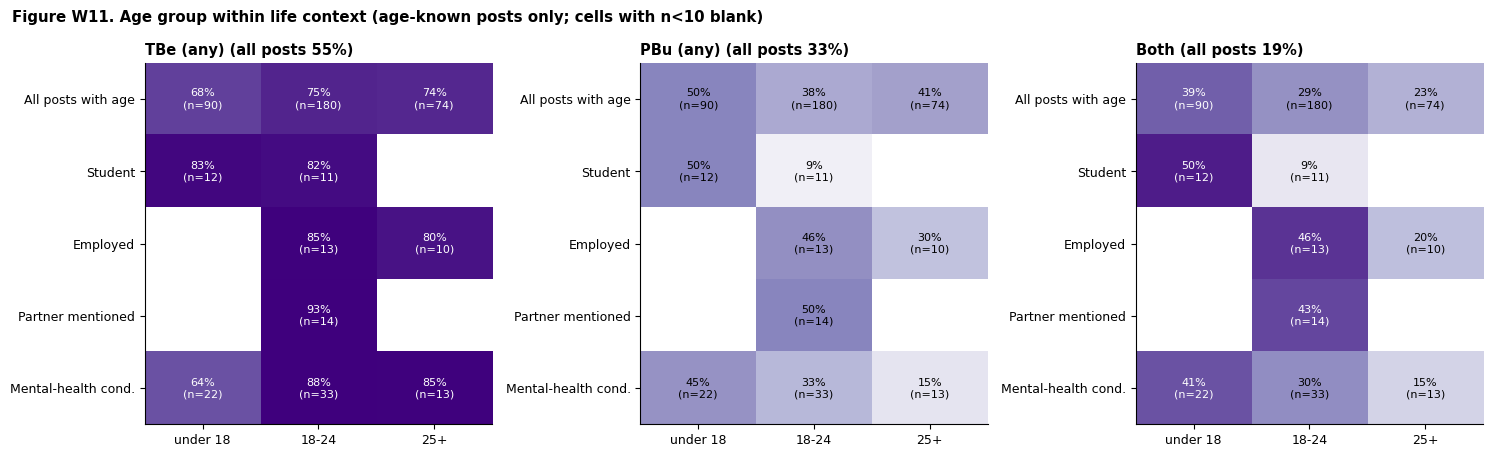

saved W11_age_by_context.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ---------- W11 age x context ----------
ctx = {"All posts with age": np.ones(N, bool), "Student": M["Student"], "Employed": M["Employed"], "Partner mentioned": M["Partner / spouse mentioned"], "Mental-health cond.": M["Mental-health condition"]}
ages = ["under 18", "18-24", "25+"]; fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, o in zip(axs, OC3):
    Mx = np.full((len(ctx), 3), np.nan); Nn = np.zeros((len(ctx), 3), int)
    for i, (cn, cm) in enumerate(ctx.items()):
        for j, a in enumerate(ages):
            m = cm & (d.age_bin == a).values; Nn[i, j] = m.sum()
            if m.sum() >= 10: Mx[i, j] = 100 * OUTC[o][m].mean()
    im = ax.imshow(Mx, cmap="Purples", vmin=0, vmax=85 if o != "Both" else 55, aspect="auto"); ax.set_xticks(range(3)); ax.set_xticklabels(ages); ax.set_yticks(range(len(ctx))); ax.set_yticklabels(ctx.keys())
    for i in range(len(ctx)):
        for j in range(3):
            if not np.isnan(Mx[i, j]): ax.text(j, i, f"{Mx[i, j]:.0f}%\n(n={Nn[i, j]})", ha="center", va="center", fontsize=8, color="white" if Mx[i, j] > (50 if o != "Both" else 33) else "k")
    ax.set_title(f"{o} (all posts {100*base[o]:.0f}%)", loc="left")
fig.suptitle("Figure W11. Age group within life context (age-known posts only; cells with n<10 blank)", x=.01, ha="left", fontweight="bold"); fig.tight_layout(); save(fig, "W11_age_by_context.png")

### Figure W12 – Typology of groups (hierarchical clustering)
**What we get:** A dendrogram and heatmap clustering groups by their outcome mix.

**Why we did it:** Groups that behave alike are clustered, giving a short typology instead of 13 separate rows.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

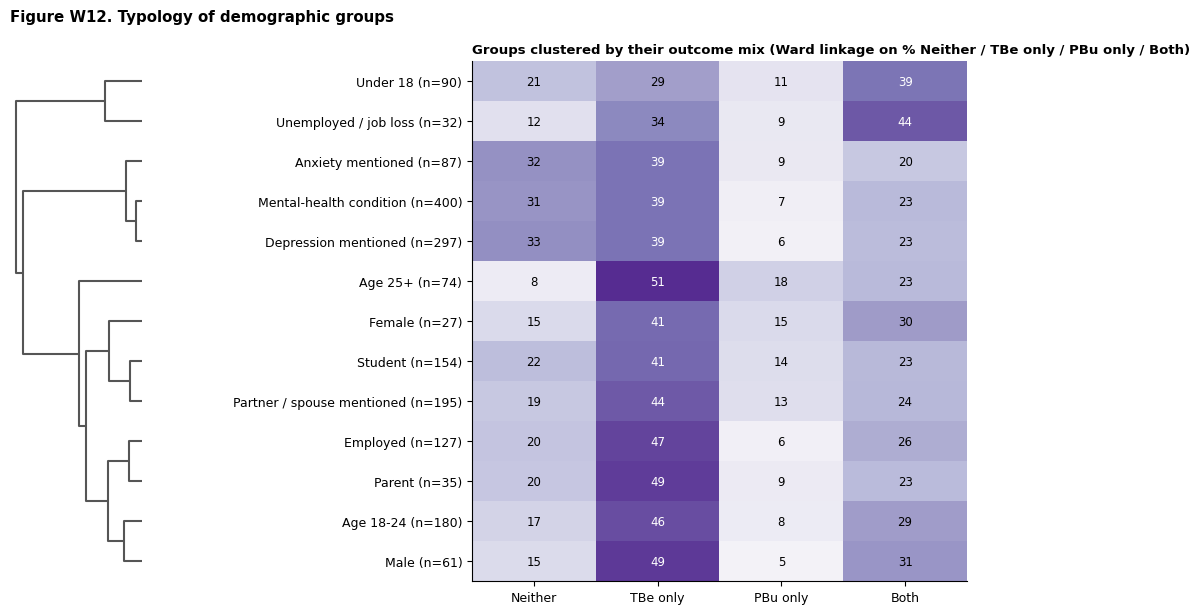

saved W12_group_typology_clustering.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ---------- W12 hierarchical clustering of groups ----------
prof = pd.DataFrame({g: {k: 100 * (out.cls[M[g]] == k).mean() for k in CL} for g in GR}).T
Z = linkage(prof.values, "ward"); lo_ = leaves_list(Z); prof_o = prof.iloc[lo_]
fig = plt.figure(figsize=(11, 6.5)); axd = fig.add_axes([.01, .1, .12, .8]); dendrogram(Z, orientation="left", ax=axd, no_labels=True, color_threshold=0, above_threshold_color="#555"); axd.invert_yaxis(); axd.axis("off")
axh = fig.add_axes([.43, .1, .45, .8]); im = axh.imshow(prof_o.values, cmap="Purples", aspect="auto", vmin=0, vmax=60); axh.set_xticks(range(4)); axh.set_xticklabels(prof_o.columns); axh.set_yticks(range(len(prof_o))); axh.set_yticklabels([f"{g} (n={ns[g]})" for g in prof_o.index])
for i in range(len(prof_o)):
    for j in range(4): axh.text(j, i, f"{prof_o.values[i, j]:.0f}", ha="center", va="center", fontsize=8.5, color="white" if prof_o.values[i, j] > 36 else "k")
axh.set_title("Groups clustered by their outcome mix (Ward linkage on % Neither / TBe only / PBu only / Both)", loc="left", fontsize=9.5); fig.suptitle("Figure W12. Typology of demographic groups", x=.01, ha="left", fontweight="bold", y=.98); save(fig, "W12_group_typology_clustering.png")

### Figure W13 – Correspondence analysis
**What we get:** A two-dimensional map of groups against the four outcome classes; closer means more over-represented.

**Why we did it:** A compact picture of the whole group by outcome table; it is descriptive only because groups overlap.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

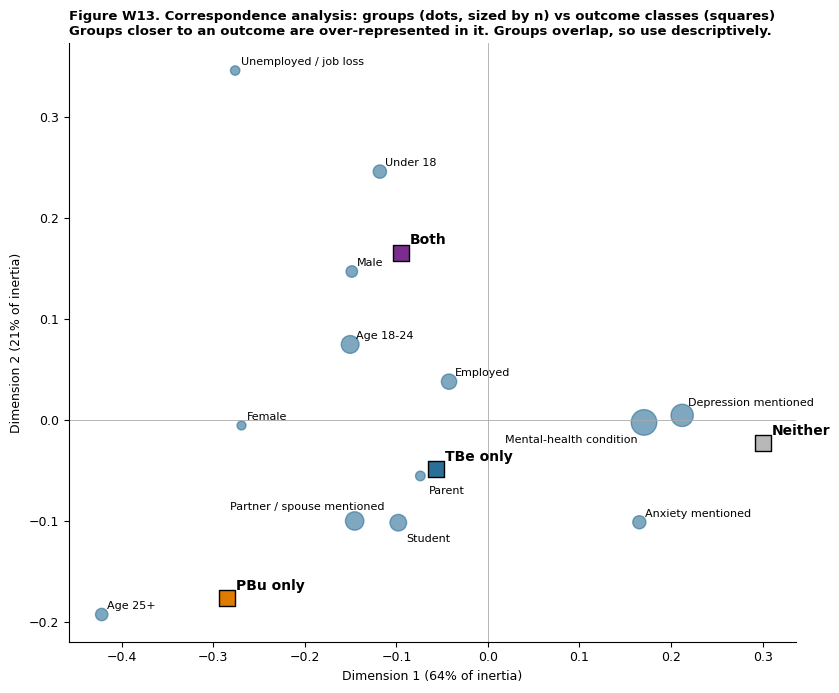

saved W13_correspondence_analysis.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ---------- W13 correspondence analysis ----------
Nm = np.array([[int((M[g] & (out.cls.values == k)).sum()) for k in CL] for g in GR], float); Pm = Nm / Nm.sum(); r = Pm.sum(1); c = Pm.sum(0)
Sm = np.diag(1 / np.sqrt(r)) @ (Pm - np.outer(r, c)) @ np.diag(1 / np.sqrt(c)); U, sv, Vt = np.linalg.svd(Sm, full_matrices=False); inertia = sv ** 2 / (sv ** 2).sum()
rowc = np.diag(1 / np.sqrt(r)) @ U * sv; colc = np.diag(1 / np.sqrt(c)) @ Vt.T * sv
fig, ax = plt.subplots(figsize=(8.5, 7)); ax.scatter(rowc[:, 0], rowc[:, 1], s=20 + Nm.sum(1) * .8, color="#2a6f97", alpha=.6)
OFF = {"Parent": (6, -13), "Student": (6, -14), "Mental-health condition": (-100, -15), "Depression mentioned": (4, 7), "Partner / spouse mentioned": (-90, 8)}
for i, g in enumerate(GR): ax.annotate(g, (rowc[i, 0], rowc[i, 1]), fontsize=8, xytext=OFF.get(g, (4, 4)), textcoords="offset points")
for j, k in enumerate(CL): ax.scatter(colc[j, 0], colc[j, 1], marker="s", s=120, color=CL[k], edgecolor="k", zorder=5); ax.annotate(k, (colc[j, 0], colc[j, 1]), fontsize=10, fontweight="bold", xytext=(6, 6), textcoords="offset points")
ax.axhline(0, color="#aaa", lw=.6); ax.axvline(0, color="#aaa", lw=.6); ax.set_xlabel(f"Dimension 1 ({100*inertia[0]:.0f}% of inertia)"); ax.set_ylabel(f"Dimension 2 ({100*inertia[1]:.0f}% of inertia)")
ax.set_title("Figure W13. Correspondence analysis: groups (dots, sized by n) vs outcome classes (squares)\nGroups closer to an outcome are over-represented in it. Groups overlap, so use descriptively.", loc="left", fontsize=9.5); fig.tight_layout(); save(fig, "W13_correspondence_analysis.png")

### Figure W14 – Rate versus reach
**What we get:** For each outcome: group rate (x) against the number of affected posts (y), bubble = group size.

**Why we did it:** A group can have a high rate but few affected people, or a modest rate but many; this separates 'most at risk' from 'most cases'.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

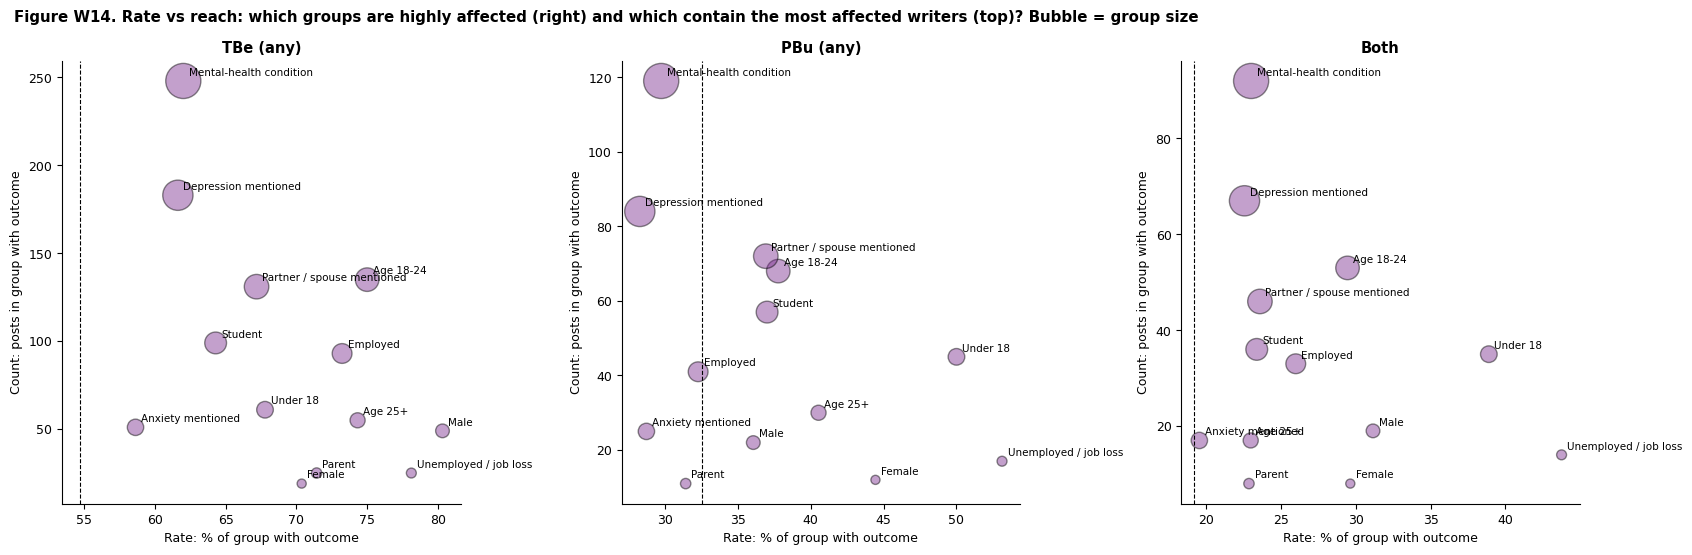

saved W14_rate_vs_reach.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ---------- W14 bubble: rate vs number of affected ----------
fig, axs = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, o in zip(axs, OC3):
    s = T[T.outcome == o]; ax.scatter(s.pct, s.k, s=s.n * 1.6, color="#7b2d8e", alpha=.45, edgecolor="k")
    for r_ in s.itertuples(): ax.annotate(r_.group, (r_.pct, r_.k), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
    ax.axvline(100 * base[o], ls="--", color="k", lw=.8); ax.set_xlabel("Rate: % of group with outcome"); ax.set_ylabel("Count: posts in group with outcome"); ax.set_title(o)
fig.suptitle("Figure W14. Rate vs reach: which groups are highly affected (right) and which contain the most affected writers (top)? Bubble = group size", x=.01, ha="left", fontweight="bold"); fig.tight_layout(); save(fig, "W14_rate_vs_reach.png")

### Figure W15 – League table
**What we get:** Rank of each group per outcome using shrunken rates, and the mean rank over TBe, PBu and Both.

**Why we did it:** One summary answering 'which groups are most affected overall' while accounting for uncertainty. (For 'Neither', rank 1 means least affected.)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

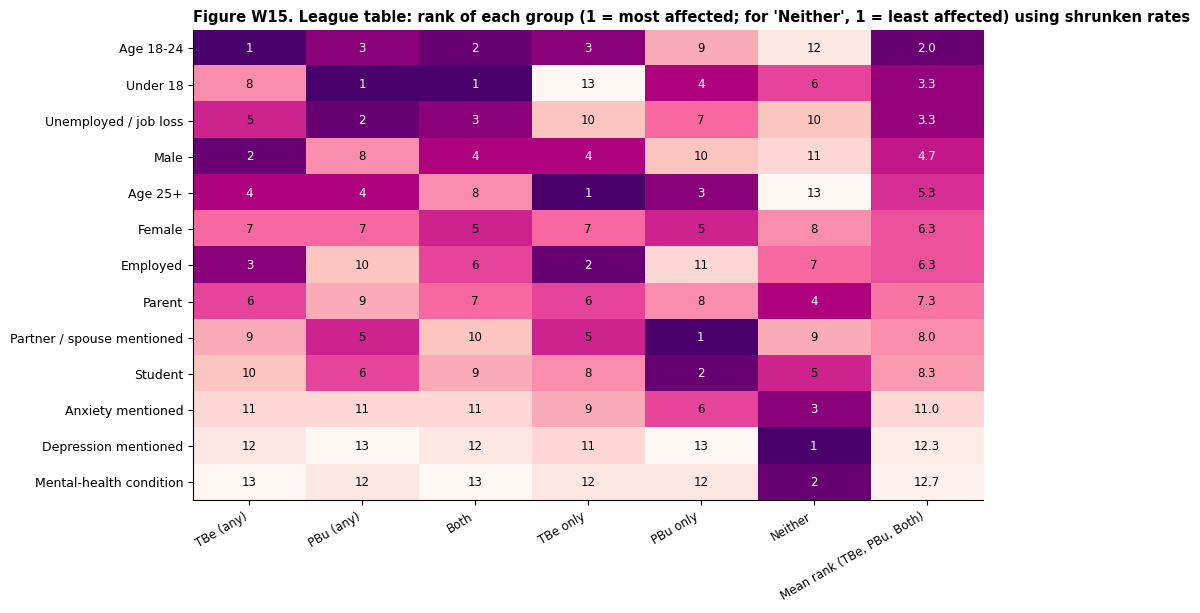

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

saved W15_league_table.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ---------- W15 league table of ranks ----------
R_ = pd.DataFrame({o: T[T.outcome == o].set_index("group").shrunk.rank(ascending=False) for o in OCH}); R_["Mean rank (TBe, PBu, Both)"] = R_[OC3].mean(axis=1); R_ = R_.sort_values("Mean rank (TBe, PBu, Both)")
fig, ax = plt.subplots(figsize=(10, 6.2)); im = ax.imshow(R_.values, cmap="RdPu_r", vmin=1, vmax=len(R_), aspect="auto")
ax.set_xticks(range(R_.shape[1])); ax.set_xticklabels(R_.columns, rotation=30, ha="right", fontsize=8.5); ax.set_yticks(range(len(R_))); ax.set_yticklabels(R_.index)
for i in range(len(R_)):
    for j in range(R_.shape[1]): ax.text(j, i, f"{R_.values[i, j]:.0f}" if j < R_.shape[1] - 1 else f"{R_.values[i, j]:.1f}", ha="center", va="center", fontsize=8.5, color="white" if R_.values[i, j] < 5 else "k")
ax.set_title("Figure W15. League table: rank of each group (1 = most affected; for 'Neither', 1 = least affected) using shrunken rates", loc="left"); fig.tight_layout(); save(fig, "W15_league_table.png")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

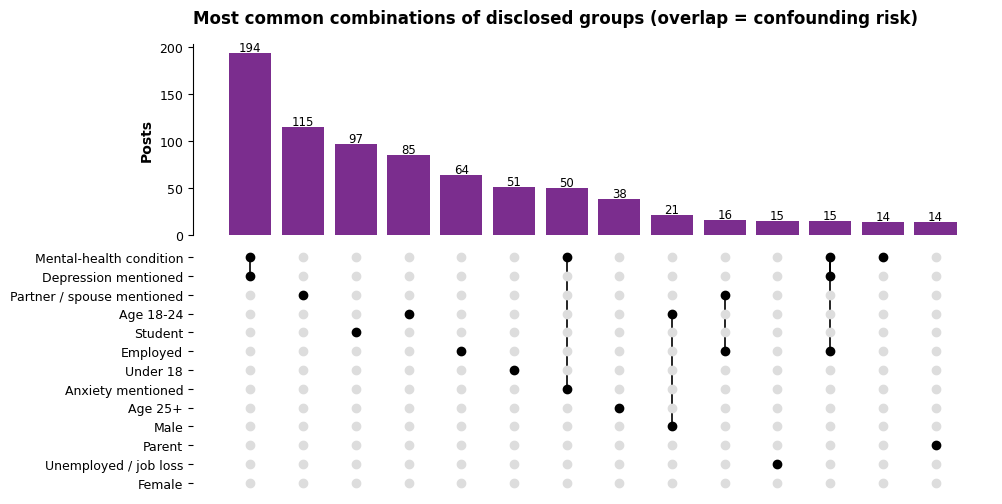

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Filter combinations with more than 0 groups and get the top 14
combo = S[GR].astype(int).apply(lambda r: tuple(c for c in GR if r[c]), axis=1)
cc = combo[combo.map(len) > 0].value_counts().head(14)

# Set up the figure for the overlap plot specifically
fig = plt.figure(figsize=(10, 6))
sub = fig.add_gridspec(2, 1, height_ratios=[1, 1.3], hspace=.05, left=0.15, right=0.95, top=0.9, bottom=0.15)
axb = fig.add_subplot(sub[0])
axm = fig.add_subplot(sub[1], sharex=axb)

# Plot the bar chart for combination counts
axb.bar(range(len(cc)), cc.values, color="#7b2d8e")
for i, v in enumerate(cc.values):
    axb.text(i, v + 2, str(v), ha="center", fontsize=8.5)
axb.set_ylabel("Posts", fontsize=10, fontweight="bold")
axb.set_xticks([])
axb.spines["bottom"].set_visible(False)
axb.set_title("Most common combinations of disclosed groups (overlap = confounding risk)", loc="left", pad=15, fontsize=12, fontweight="bold")

# Sort the groups for the vertical axis by overall frequency
gl = sorted(GR, key=lambda g: -M[g].sum())

# Plot the dot matrix showing which groups are in each combination
for i, cmb in enumerate(cc.index):
    ys = [gl.index(c) for c in cmb]
    axm.plot([i] * len(ys), ys, "-", color="k", lw=1.2)
    for y_ in range(len(gl)):
        axm.plot(i, y_, "o", color="k" if y_ in ys else "#dddddd", ms=6)

axm.set_yticks(range(len(gl)))
axm.set_yticklabels(gl, fontsize=9)
axm.set_xticks([])
axm.invert_yaxis()
axm.spines["bottom"].set_visible(False)
axm.spines["left"].set_visible(False)

# Save and display this visualization separately
fig.savefig(OUT + "W01_combinations_only.png", dpi=170, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)


## 4. Download everything

In [ ]:
import shutil, glob
print(len(glob.glob(OUT + "*.png")), "figures")
shutil.make_archive("who_figures", "zip", "outputs/who")
try:
    from google.colab import files; files.download("RQ3.zip")
except ImportError: print("Saved who_figures.zip")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

16 figures


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag